# San Francisco Neighborhood Accessibility

## Setup
This notebook uses pandas, GeoPandas, Matplotlib, Requests, and OSMnx.

Before running the notebook, activate the project's `.venv` environment
and install the packages listed in `requirements.txt`.
Select that environment as the notebook's Python kernel.

In [1]:
# Confirm which Python environment is running this notebook.
import sys
from pathlib import Path

print("Python executable:", sys.executable)
print("Working folder:", Path.cwd())

Python executable: /Users/prabhavpagadala/Documents/CyPlan101/Project/cyplan-101-project/.venv/bin/python
Working folder: /Users/prabhavpagadala/Documents/CyPlan101/Project/cyplan-101-project


In [2]:
# Load the packages used for data analysis, maps, and Census requests.
from pathlib import Path
import os

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests

# Display maps and charts directly below notebook cells.
%matplotlib inline

In [3]:
# Use a relative path so the project can run on another computer.
neighborhood_file = Path("data/analysis_neighborhoods.geojson")

# Check that the boundary file is available before loading it.
if not neighborhood_file.is_file():
    raise FileNotFoundError(
        f"Neighborhood boundary file not found: {neighborhood_file}"
    )

# Load San Francisco's analysis neighborhood boundaries.
neighborhoods = gpd.read_file(neighborhood_file)

print("Number of neighborhoods:", len(neighborhoods))
print("Original CRS:", neighborhoods.crs)
display(neighborhoods[["nhood", "geometry"]].head())

Number of neighborhoods: 41
Original CRS: EPSG:4326


,nhood,geometry
0,Western Addition,"MULTIPOLYGON (((-122.42144 37.78557, -122.4213..."
1,West of Twin Peaks,"MULTIPOLYGON (((-122.46104 37.75096, -122.4605..."
2,Visitacion Valley,"MULTIPOLYGON (((-122.40385 37.71883, -122.4035..."
3,Twin Peaks,"MULTIPOLYGON (((-122.44695 37.75655, -122.4459..."
4,South of Market,"MULTIPOLYGON (((-122.40371 37.78404, -122.4027..."


## Neighborhood boundaries

We use San Francisco’s 41 analysis neighborhoods as our study areas.
Before spatial analysis, we check neighborhood names and geometries
for missing values, duplicates, and invalid shapes.

In [4]:
# Check the boundaries before using them in spatial calculations.
neighborhood_checks = pd.Series({
    "Total neighborhoods": len(neighborhoods),
    "Missing neighborhood names": neighborhoods["nhood"].isna().sum(),
    "Duplicate neighborhood names": (
        neighborhoods["nhood"].duplicated().sum()
    ),
    "Missing geometries": neighborhoods.geometry.isna().sum(),
    "Empty geometries": neighborhoods.geometry.is_empty.sum(),
    "Invalid nonmissing geometries": (
        neighborhoods.geometry.notna()
        & ~neighborhoods.geometry.is_valid
    ).sum()
})

display(neighborhood_checks)

Total neighborhoods              41
Missing neighborhood names        0
Duplicate neighborhood names      0
Missing geometries                0
Empty geometries                  0
Invalid nonmissing geometries     0
dtype: int64

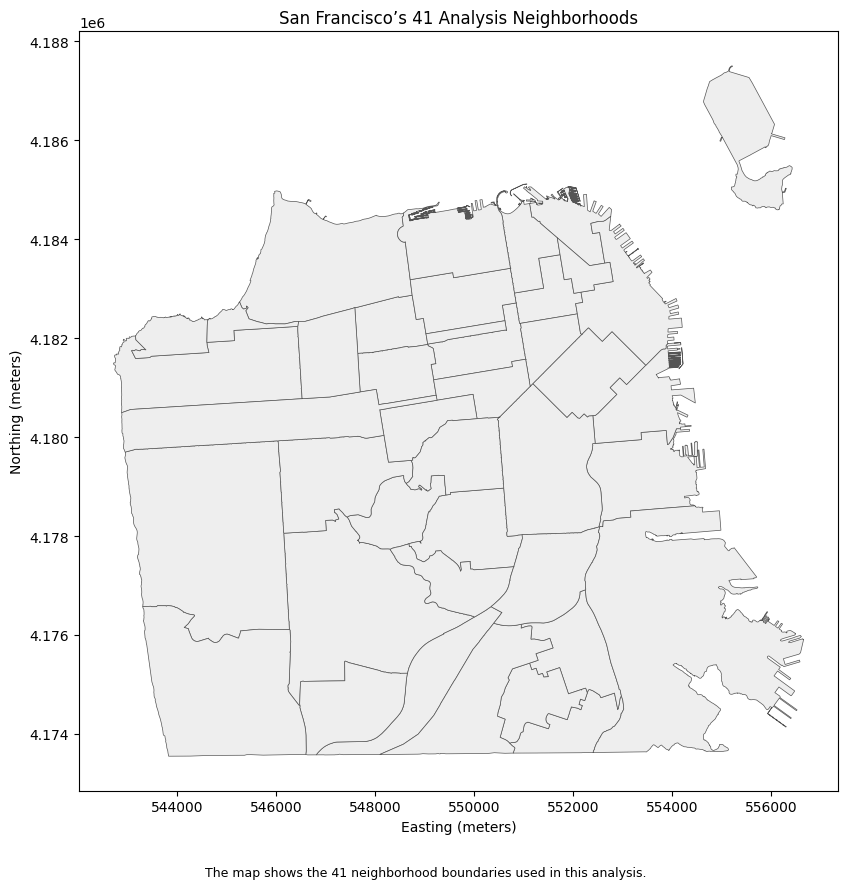

Projected CRS: EPSG:26910


In [5]:
# Convert longitude/latitude coordinates to a projected CRS in meters.
neighborhoods_projected = neighborhoods.to_crs(epsg=26910)

# Draw the study area's neighborhood boundaries.
fig, ax = plt.subplots(figsize=(9, 9))

neighborhoods_projected.plot(
    ax=ax,
    color="#eeeeee",
    edgecolor="#555555",
    linewidth=0.5
)

ax.set_title("San Francisco’s 41 Analysis Neighborhoods")
ax.set_xlabel("Easting (meters)")
ax.set_ylabel("Northing (meters)")

fig.text(
    0.5, 0.02,
    "The map shows the 41 neighborhood boundaries used in this analysis.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

print("Projected CRS:", neighborhoods_projected.crs)

## Census income and household data

We use the 2024 ACS five-year estimates, covering 2020–2024, for
San Francisco census tracts. These include median household income,
total households, and their margins of error. We inspect and clean
these values before attaching them to tract boundaries.

In [6]:
# Reuse the original Census response saved during the earlier analysis.
raw_dir = Path("data/raw")
acs_raw_file = raw_dir / "acs_2024_sf_tracts_raw.csv"

# Read as text to preserve leading zeros in Census geographic codes.
income_raw = pd.read_csv(acs_raw_file, dtype=str)

print("Census tract records loaded:", len(income_raw))
display(income_raw.head())

Census tract records loaded: 244


,NAME,B19013_001E,B19013_001M,B11001_001E,B11001_001M,state,county,tract
0,Census Tract 101.01; San Francisco County; Cal...,89022,40627,1216,150,06,075,010101
1,Census Tract 101.02; San Francisco County; Cal...,102826,55857,930,211,06,075,010102
2,Census Tract 102.01; San Francisco County; Cal...,156017,4484,1399,179,06,075,010201
3,Census Tract 102.02; San Francisco County; Cal...,176958,57906,1099,174,06,075,010202
4,Census Tract 103; San Francisco County; Califo...,158144,24737,2060,340,06,075,010300


In [7]:
# Give the Census variables readable names.
income = income_raw.rename(columns={
    "B19013_001E": "median_income",
    "B19013_001M": "income_moe",
    "B11001_001E": "households",
    "B11001_001M": "households_moe"
}).copy()

# Convert estimates and margins of error from text to numbers.
numeric_columns = [
    "median_income",
    "income_moe",
    "households",
    "households_moe"
]

for column in numeric_columns:
    income[column] = pd.to_numeric(income[column], errors="coerce")

# Combine geographic codes into each tract's unique Census identifier.
income["GEOID"] = (
    income["state"] + income["county"] + income["tract"]
)

# Count potential data issues before replacing or removing anything.
income_checks = pd.DataFrame({
    "Missing values": income[numeric_columns].isna().sum(),
    "Negative values": income[numeric_columns].lt(0).sum(),
    "Zero values": income[numeric_columns].eq(0).sum()
})

display(income_checks)

print("Total tract records:", len(income))
print("Duplicate GEOIDs:", income["GEOID"].duplicated().sum())
print("Rows removed so far: 0")

,Missing values,Negative values,Zero values
median_income,0,10,0
income_moe,0,20,0
households,0,0,4
households_moe,0,0,0


Total tract records: 244
Duplicate GEOIDs: 0
Rows removed so far: 0


In [8]:
# Keep the original table unchanged for comparison.
income_clean = income.copy()

# Flag medians in an open-ended income interval BEFORE replacing codes.
# Their reported income values represent bounds rather than exact medians.
income_clean["income_open_ended"] = (
    income_clean["income_moe"].eq(-333333333)
)

# Census codes representing missing values or special conditions.
special_codes = [
    -666666666,
    -999999999,
    -888888888,
    -222222222,
    -333333333,
    -555555555
]

# Replace special codes and document how many values were affected.
cleaning_records = []

for column in numeric_columns:
    special_mask = income_clean[column].isin(special_codes)

    cleaning_records.append({
        "column": column,
        "special_codes_replaced": int(special_mask.sum())
    })

    income_clean.loc[special_mask, column] = float("nan")

acs_cleaning_log = pd.DataFrame(cleaning_records)

# Stop if an unexpected negative value remains.
assert not income_clean[numeric_columns].lt(0).any().any(), (
    "Unexpected negative values remain. Inspect them before continuing."
)

# Income weighting requires an income estimate and positive households.
# A missing margin of error alone does not exclude an income estimate.
income_clean["eligible_for_income_weighting"] = (
    income_clean["median_income"].notna()
    & income_clean["households"].notna()
    & income_clean["households"].gt(0)
)

display(acs_cleaning_log)

print("Tracts retained:", len(income_clean))
print(
    "Eligible for income weighting:",
    income_clean["eligible_for_income_weighting"].sum()
)
print(
    "Open-ended income estimates:",
    income_clean["income_open_ended"].sum()
)

,column,special_codes_replaced
0,median_income,10
1,income_moe,20
2,households,0
3,households_moe,0


Tracts retained: 244
Eligible for income weighting: 234
Open-ended income estimates: 10


In [9]:
def download_if_missing(url, destination):
    """Download a source file only when no local copy exists."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.is_file():
        print("Using existing file:", destination)
    else:
        print("Downloading:", destination)
        response = requests.get(url, timeout=120)
        response.raise_for_status()
        destination.write_bytes(response.content)

    return destination


# California's 2024 Census tract boundaries.
tract_url = (
    "https://www2.census.gov/geo/tiger/"
    "TIGER2024/TRACT/tl_2024_06_tract.zip"
)

tract_file = download_if_missing(
    tract_url,
    raw_dir / "ca_census_tracts.zip"
)

# Read the statewide boundaries.
tracts_ca = gpd.read_file(tract_file)

# Keep only San Francisco County: California 06, county 075.
sf_mask = (
    tracts_ca["STATEFP"].eq("06")
    & tracts_ca["COUNTYFP"].eq("075")
)
tracts = tracts_ca.loc[sf_mask].copy()

# Document the geographic filtering and check tract identifiers.
print("California tract boundaries:", len(tracts_ca))
print("Outside San Francisco, filtered out:", (~sf_mask).sum())
print("San Francisco tract boundaries retained:", len(tracts))
print("Duplicate SF GEOIDs:", tracts["GEOID"].duplicated().sum())
print("Original tract CRS:", tracts.crs)

Using existing file: data/raw/ca_census_tracts.zip
California tract boundaries: 9129
Outside San Francisco, filtered out: 8885
San Francisco tract boundaries retained: 244
Duplicate SF GEOIDs: 0
Original tract CRS: EPSG:4269


In [10]:
# Select the Census fields needed for the analysis.
income_columns = [
    "GEOID",
    "median_income",
    "income_moe",
    "households",
    "households_moe",
    "income_open_ended",
    "eligible_for_income_weighting"
]

# Attach Census statistics to tract polygons using their shared ID.
# one_to_one prevents duplicate IDs from multiplying records.
# The indicator records whether each boundary found a Census match.
tracts_income = tracts.merge(
    income_clean[income_columns],
    on="GEOID",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Check matching and geometry before spatial calculations.
tract_checks = pd.Series({
    "Tract boundaries retained": len(tracts_income),
    "Boundaries matched to Census data": (
        tracts_income["_merge"] == "both"
    ).sum(),
    "Boundaries without a Census match": (
        tracts_income["_merge"] == "left_only"
    ).sum(),
    "Census records without a boundary": (
        ~income_clean["GEOID"].isin(tracts["GEOID"])
    ).sum(),
    "Missing geometries": tracts_income.geometry.isna().sum(),
    "Empty geometries": tracts_income.geometry.is_empty.sum(),
    "Invalid nonmissing geometries": (
        tracts_income.geometry.notna()
        & ~tracts_income.geometry.is_valid
    ).sum()
})

display(tract_checks)

Tract boundaries retained            244
Boundaries matched to Census data    244
Boundaries without a Census match      0
Census records without a boundary      0
Missing geometries                     0
Empty geometries                       0
Invalid nonmissing geometries          0
dtype: int64

## Estimating neighborhood income

We intersect Census tracts with neighborhood boundaries to estimate how
tract households are distributed among neighborhoods. We first inspect
area coverage and allocation gaps before calculating household-weighted
averages of tract median incomes. These are approximate neighborhood
income measures, not official neighborhood medians.

In [11]:
# Project tract boundaries into the same meter-based CRS as neighborhoods.
tracts_projected = (
    tracts_income.drop(columns="_merge")
    .to_crs(epsg=26910)
)

# Measure each tract's full polygon area.
# This includes any water within the tract boundary, not just land.
tracts_projected["tract_area_m2"] = (
    tracts_projected.geometry.area
)

# Split tracts wherever they intersect neighborhood boundaries.
# Keep the Census fields needed for household allocation and quality checks.
overlaps = gpd.overlay(
    neighborhoods_projected[["nhood", "geometry"]],
    tracts_projected[
        income_columns + ["tract_area_m2", "geometry"]
    ],
    how="intersection",
    keep_geom_type=True
)

# Measure each neighborhood–tract intersection in square meters.
overlaps["overlap_area_m2"] = overlaps.geometry.area

print("Neighborhood–tract overlap pieces:", len(overlaps))
print("Neighborhoods represented:", overlaps["nhood"].nunique())
print("Tracts represented:", overlaps["GEOID"].nunique())
print(
    "Pieces with zero or negative area:",
    overlaps["overlap_area_m2"].le(0).sum()
)

display(
    overlaps[
        ["nhood", "GEOID", "median_income", "households",
         "tract_area_m2", "overlap_area_m2"]
    ].head()
)

Neighborhood–tract overlap pieces: 630
Neighborhoods represented: 41
Tracts represented: 242
Pieces with zero or negative area: 0


,nhood,GEOID,median_income,households,tract_area_m2,overlap_area_m2
0,Western Addition,06075012202,57897.0,1374.0,94614.688719,1905.580193
1,Western Addition,06075013102,250001.0,1482.0,237711.993608,2.979060
2,Western Addition,06075015801,121563.0,1527.0,343679.470065,343295.573861
3,Western Addition,06075015100,159921.0,1566.0,171870.833702,171868.655030
4,Western Addition,06075015900,83866.0,2081.0,295359.785565,294896.646992


In [12]:
# Sum the neighborhood-covered area within each tract.
covered_area_by_tract = (
    overlaps.groupby("GEOID")["overlap_area_m2"].sum()
)

# Keep all tracts in this check, including those without overlaps.
tract_coverage = tracts_projected[
    ["GEOID", "NAME", "households", "median_income", "tract_area_m2"]
].copy()

tract_coverage["covered_area_m2"] = (
    tract_coverage["GEOID"]
    .map(covered_area_by_tract)
    .fillna(0)
)

# Calculate the fraction of each tract covered by neighborhoods.
tract_coverage["covered_share"] = (
    tract_coverage["covered_area_m2"]
    / tract_coverage["tract_area_m2"]
)

no_overlap = tract_coverage["covered_area_m2"].eq(0)

# Allow a small tolerance for numerical rounding.
over_covered = tract_coverage["covered_share"].gt(1 + 1e-6)

print("Tracts without neighborhood overlaps:", no_overlap.sum())
print("Tracts with coverage above 100%:", over_covered.sum())

print("\nTracts without neighborhood overlaps:")
display(
    tract_coverage.loc[
        no_overlap,
        ["GEOID", "NAME", "households", "median_income", "covered_share"]
    ]
)

print("\nCoverage-share summary across all tracts:")
display(tract_coverage["covered_share"].describe())

Tracts without neighborhood overlaps: 2
Tracts with coverage above 100%: 0

Tracts without neighborhood overlaps:


,GEOID,NAME,households,median_income,covered_share
31,06075980401,9804.01,0.0,NaN,0.0
195,06075990100,9901,0.0,NaN,0.0



Coverage-share summary across all tracts:


count    244.000000
mean       0.951586
std        0.164954
min        0.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: covered_share, dtype: float64

In [13]:
# Calculate each intersection's share of its original tract area.
overlaps["tract_area_share"] = (
    overlaps["overlap_area_m2"]
    / overlaps["tract_area_m2"]
)

# Allocate tract households using that area share.
overlaps["estimated_households"] = (
    overlaps["households"]
    * overlaps["tract_area_share"]
)

# Compare allocated households with the original Census total.
source_households = tracts_projected["households"].sum()
allocated_households = overlaps["estimated_households"].sum()

# Count allocated households associated with usable income estimates.
allocated_with_income = overlaps.loc[
    overlaps["eligible_for_income_weighting"],
    "estimated_households"
].sum()

print(f"Original SF household estimate: {source_households:,.0f}")
print(
    "Households allocated to neighborhoods:",
    f"{allocated_households:,.1f}"
)
print(
    "Household allocation coverage:",
    f"{100 * allocated_households / source_households:.2f}%"
)
print(
    "Share of allocated households with usable income:",
    f"{100 * allocated_with_income / allocated_households:.2f}%"
)

display(
    overlaps[
        ["nhood", "GEOID", "households",
         "tract_area_share", "estimated_households"]
    ].head()
)

Original SF household estimate: 363,970
Households allocated to neighborhoods: 351,875.0
Household allocation coverage: 96.68%
Share of allocated households with usable income: 98.26%


,nhood,GEOID,households,tract_area_share,estimated_households
0,Western Addition,06075012202,1374.0,0.020140,27.672946
1,Western Addition,06075013102,1482.0,0.000013,0.018573
2,Western Addition,06075015801,1527.0,0.998883,1525.294313
3,Western Addition,06075015100,1566.0,0.999987,1565.980149
4,Western Addition,06075015900,2081.0,0.998432,2077.736890


In [14]:
# Sum the households allocated from each tract to neighborhoods.
allocated_by_tract = (
    overlaps.groupby("GEOID")["estimated_households"].sum()
)

# Attach those totals to the coverage table, retaining all 244 tracts.
tract_coverage["allocated_households"] = (
    tract_coverage["GEOID"]
    .map(allocated_by_tract)
    .fillna(0)
)

# Measure the difference from each tract's original household estimate.
tract_coverage["unallocated_households"] = (
    tract_coverage["households"]
    - tract_coverage["allocated_households"]
)

# Identify the ten tracts contributing the largest allocation gaps.
largest_gaps = (
    tract_coverage.sort_values(
        "unallocated_households",
        ascending=False
    )
    .head(10)
    .copy()
)

display(
    largest_gaps[
        ["GEOID", "NAME", "households", "covered_share",
         "allocated_households", "unallocated_households"]
    ].round(4)
)

print(
    "Total estimated households unallocated:",
    f"{tract_coverage['unallocated_households'].sum():,.1f}"
)

,GEOID,NAME,households,covered_share,allocated_households,unallocated_households
141,06075060701,607.01,3635.0,0.5972,2170.8167,1464.1833
156,06075047904,479.04,1380.0,0.1544,213.0282,1166.9718
225,06075060100,601,1346.0,0.2312,311.2166,1034.7834
215,06075035400,354,2477.0,0.6489,1607.4142,869.5858
58,06075010500,105,1848.0,0.5815,1074.5455,773.4545
213,06075035201,352.01,1915.0,0.5986,1146.4013,768.5987
7,06075012602,126.02,1470.0,0.5359,787.7263,682.2737
238,06075022600,226,2257.0,0.7049,1591.0645,665.9355
65,06075012700,127,1996.0,0.6834,1364.0660,631.9340
139,06075010101,101.01,1216.0,0.5141,625.1351,590.8649


Total estimated households unallocated: 12,095.0


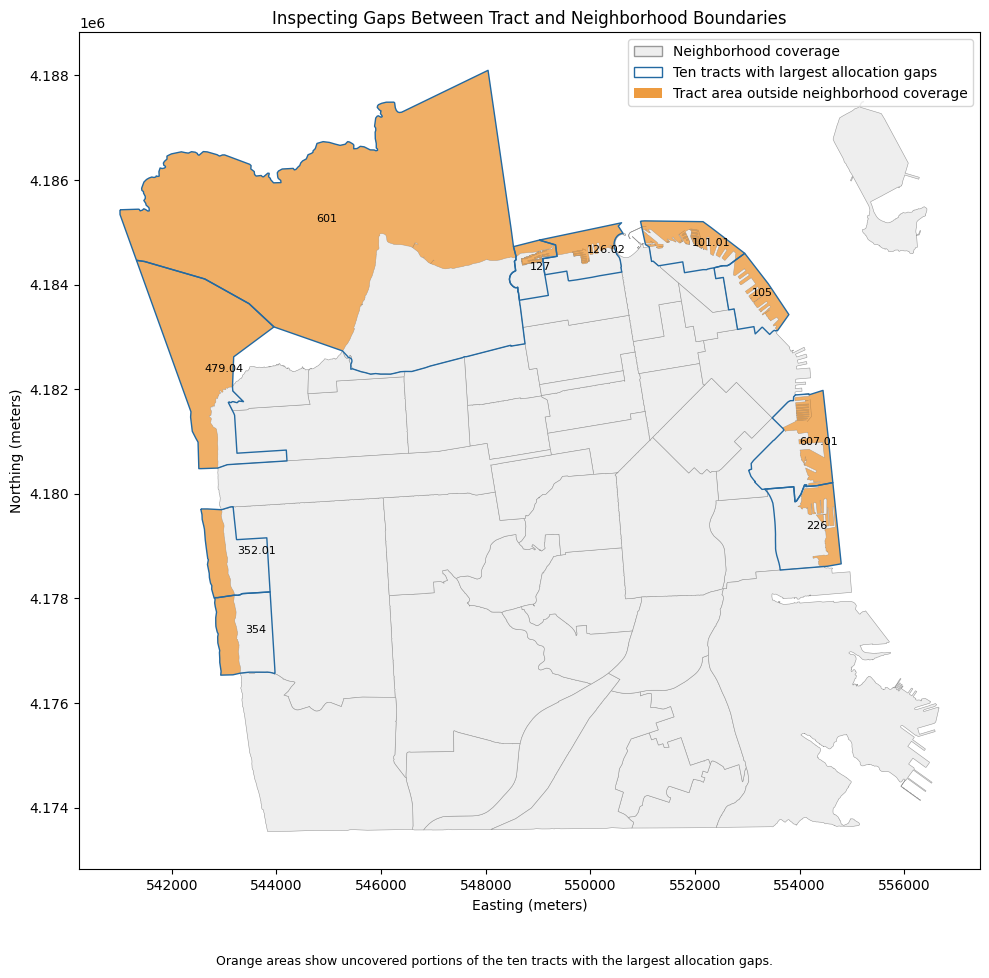

In [15]:
from matplotlib.patches import Patch

# Select the ten tracts with the largest household-allocation gaps.
gap_tracts = tracts_projected.loc[
    tracts_projected["GEOID"].isin(largest_gaps["GEOID"])
].copy()

# Find portions of those tracts outside all neighborhood polygons.
uncovered_parts = gpd.overlay(
    gap_tracts[["GEOID", "geometry"]],
    neighborhoods_projected[["geometry"]],
    how="difference",
    keep_geom_type=True
)

# Compare neighborhood coverage with the original tract footprints.
fig, ax = plt.subplots(figsize=(10, 10))

neighborhoods_projected.plot(
    ax=ax, color="#eeeeee", edgecolor="#999999", linewidth=0.4
)

uncovered_parts.plot(
    ax=ax, color="#ed9b40", edgecolor="none", alpha=0.8
)

gap_tracts.boundary.plot(
    ax=ax, color="#2369a1", linewidth=1
)

# Label the selected tracts using their Census tract names.
for _, row in gap_tracts.iterrows():
    point = row.geometry.representative_point()
    ax.annotate(
        row["NAME"],
        (point.x, point.y),
        fontsize=8
    )

ax.legend(handles=[
    Patch(
        facecolor="#eeeeee", edgecolor="#999999",
        label="Neighborhood coverage"
    ),
    Patch(
        facecolor="none", edgecolor="#2369a1",
        label="Ten tracts with largest allocation gaps"
    ),
    Patch(
        facecolor="#ed9b40",
        label="Tract area outside neighborhood coverage"
    )
])

ax.set_title("Inspecting Gaps Between Tract and Neighborhood Boundaries")
ax.set_xlabel("Easting (meters)")
ax.set_ylabel("Northing (meters)")

fig.text(
    0.5, 0.02,
    "Orange areas show uncovered portions of the ten tracts with the largest allocation gaps.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

In [16]:
# Attach Census land and water areas to the ten largest-gap tracts.
water_check = largest_gaps[
    ["GEOID", "NAME", "covered_share"]
].merge(
    tracts_projected[["GEOID", "ALAND", "AWATER"]],
    on="GEOID",
    how="left",
    validate="one_to_one"
)

# Percentage of each tract outside neighborhood coverage.
water_check["uncovered_area_pct"] = (
    100 * (1 - water_check["covered_share"])
)

# Percentage of each tract classified as water by the Census.
water_check["water_area_pct"] = (
    100 * water_check["AWATER"]
    / (water_check["ALAND"] + water_check["AWATER"])
)

display(
    water_check[
        ["GEOID", "NAME", "uncovered_area_pct", "water_area_pct"]
    ].round(2)
)

,GEOID,NAME,uncovered_area_pct,water_area_pct
0,06075060701,607.01,40.28,42.70
1,06075047904,479.04,84.56,84.10
2,06075060100,601,76.88,76.84
3,06075035400,354,35.11,35.11
4,06075010500,105,41.85,42.60
5,06075035201,352.01,40.14,40.14
6,06075012602,126.02,46.41,46.88
7,06075022600,226,29.51,30.32
8,06075012700,127,31.66,36.85
9,06075010101,101.01,48.59,50.32


The initial allocation left approximately 12,095 households unallocated.
A map inspection and comparison with Census water-area totals suggest
that coastal water explains much of the uncovered tract area.

We therefore allocate each tract's households in proportion to its area
covered by neighborhoods. This assumes uncovered portions contain no
households and households are evenly distributed across covered portions.
It preserves tract household totals by construction, but does not locate
residences or remove parks and other nonresidential land.

In [17]:
# Sum the neighborhood-covered area within each tract.
covered_area_per_piece = (
    overlaps.groupby("GEOID")["overlap_area_m2"].transform("sum")
)

# Calculate each piece's share of its tract's covered area.
overlaps["covered_area_share"] = (
    overlaps["overlap_area_m2"]
    / covered_area_per_piece
)

# Allocate households across the covered portions of each tract.
# Preserve estimated_households as the original baseline.
overlaps["estimated_households_adjusted"] = (
    overlaps["households"]
    * overlaps["covered_area_share"]
)

# Compare adjusted household totals with the original Census totals.
adjusted_by_tract = (
    overlaps.groupby("GEOID")["estimated_households_adjusted"].sum()
)

tract_coverage["adjusted_allocated_households"] = (
    tract_coverage["GEOID"]
    .map(adjusted_by_tract)
    .fillna(0)
)

# Check every tract, including the two without neighborhood overlaps.
household_discrepancy = (
    tract_coverage["adjusted_allocated_households"]
    - tract_coverage["households"]
)

print(f"Original Census households: {source_households:,.1f}")
print(f"Original allocation: {allocated_households:,.1f}")
print(
    "Adjusted allocation:",
    f"{overlaps['estimated_households_adjusted'].sum():,.1f}"
)
print(
    "Tracts with household-total discrepancies:",
    household_discrepancy.abs().gt(1e-6).sum()
)

Original Census households: 363,970.0
Original allocation: 351,875.0
Adjusted allocation: 363,970.0
Tracts with household-total discrepancies: 0


In [20]:
def summarize_neighborhood_income(data, household_column):
    """Summarize household-weighted tract incomes by neighborhood."""
    work = data.copy()

    # Retain all allocated households for the coverage calculation.
    work["allocated_households"] = work[household_column]

    # Only households with usable income contribute to income weights.
    work["households_with_income"] = work[household_column].where(
        work["eligible_for_income_weighting"], 0
    )

    work["income_numerator"] = (
        work["median_income"] * work["households_with_income"]
    ).fillna(0)

    # Track the weight contributed by open-ended income estimates.
    work["open_ended_households"] = work["households_with_income"].where(
        work["income_open_ended"], 0
    )

    summary = work.groupby("nhood", as_index=False).agg(
        estimated_households=("allocated_households", "sum"),
        households_with_income=("households_with_income", "sum"),
        income_numerator=("income_numerator", "sum"),
        open_ended_households=("open_ended_households", "sum")
    )

    # Zero denominators become missing rather than producing invalid ratios.
    income_denominator = summary["households_with_income"].where(
        summary["households_with_income"].gt(0)
    )
    total_denominator = summary["estimated_households"].where(
        summary["estimated_households"].gt(0)
    )

    summary["estimated_income"] = (
        summary["income_numerator"] / income_denominator
    )
    summary["income_coverage_pct"] = (
        100 * summary["households_with_income"] / total_denominator
    )
    summary["open_ended_weight_pct"] = (
        100 * summary["open_ended_households"] / income_denominator
    )

    return summary.drop(columns="income_numerator")


# Apply the same calculation to the original and adjusted allocations.
neighborhood_income_original = summarize_neighborhood_income(
    overlaps, "estimated_households"
)

neighborhood_income_adjusted = summarize_neighborhood_income(
    overlaps, "estimated_households_adjusted"
)

print("Neighborhoods summarized:", len(neighborhood_income_adjusted))
print(
    "Neighborhoods without a usable income estimate:",
    neighborhood_income_adjusted["estimated_income"].isna().sum()
)

# Inspect neighborhoods with the lowest income-data coverage first.
display(
    neighborhood_income_adjusted.sort_values("income_coverage_pct")[
        ["nhood", "estimated_households", "estimated_income",
         "income_coverage_pct", "open_ended_weight_pct"]
    ].head(10).round(2)
)

Neighborhoods summarized: 41
Neighborhoods without a usable income estimate: 0


,nhood,estimated_households,estimated_income,income_coverage_pct,open_ended_weight_pct
35,Tenderloin,18120.35,53338.05,79.51,0.00
13,Lakeshore,4867.72,70924.54,86.89,0.00
33,South of Market,13799.09,112576.65,88.86,0.00
0,Bayview Hunters Point,12275.31,95662.16,98.06,0.00
5,Financial District/South Beach,14227.96,183869.83,99.96,21.75
40,Western Addition,11237.05,104538.73,99.97,0.00
1,Bernal Heights,9167.86,183079.24,100.00,0.00
34,Sunset/Parkside,27113.99,149321.83,100.00,0.00
28,Potrero Hill,7631.14,223319.56,100.00,36.97
4,Excelsior,11109.15,117684.79,100.00,0.00


In [21]:
# Match each neighborhood's original and adjusted income estimates.
income_comparison = (
    neighborhood_income_original[
        ["nhood", "estimated_income"]
    ]
    .rename(columns={"estimated_income": "original_income"})
    .merge(
        neighborhood_income_adjusted[
            ["nhood", "estimated_income",
             "income_coverage_pct", "open_ended_weight_pct"]
        ].rename(columns={"estimated_income": "adjusted_income"}),
        on="nhood",
        how="inner",
        validate="one_to_one"
    )
)

# Measure the change in dollars and as a percentage of the original.
income_comparison["change_dollars"] = (
    income_comparison["adjusted_income"]
    - income_comparison["original_income"]
)

income_comparison["change_pct"] = (
    100 * income_comparison["change_dollars"]
    / income_comparison["original_income"]
)

# Absolute changes measure the size of the difference in either direction.
income_comparison["absolute_change_pct"] = (
    income_comparison["change_pct"].abs()
)

print(
    "Median absolute percentage change:",
    f"{income_comparison['absolute_change_pct'].median():.2f}%"
)
print(
    "Largest absolute percentage change:",
    f"{income_comparison['absolute_change_pct'].max():.2f}%"
)

# Inspect the ten neighborhoods most affected by the adjustment.
display(
    income_comparison.sort_values(
        "absolute_change_pct", ascending=False
    )[
        ["nhood", "original_income", "adjusted_income",
         "change_dollars", "change_pct", "income_coverage_pct"]
    ].head(10).round(2)
)

Median absolute percentage change: 0.00%
Largest absolute percentage change: 5.52%


,nhood,original_income,adjusted_income,change_dollars,change_pct,income_coverage_pct
14,Lincoln Park,136389.09,143918.34,7529.25,5.52,100.00
19,Mission Bay,190146.87,197815.55,7668.68,4.03,100.00
22,North Beach,129209.92,125288.27,-3921.66,-3.04,100.00
0,Bayview Hunters Point,94034.57,95662.16,1627.59,1.73,98.06
5,Financial District/South Beach,186961.51,183869.83,-3091.68,-1.65,99.96
25,Outer Richmond,137176.22,135233.19,-1943.03,-1.42,100.00
16,Marina,212547.68,215421.05,2873.38,1.35,100.00
31,Russian Hill,157063.68,158093.81,1030.13,0.66,100.00
13,Lakeshore,70636.27,70924.54,288.27,0.41,86.89
7,Golden Gate Park,124631.05,124146.67,-484.38,-0.39,100.00


## Income groups and case selection

We divide all 41 neighborhoods into three relative income groups using
the adjusted income estimates. These groups describe neighborhood
rankings within San Francisco, not official income or affordability categories.

We compare group assignments under both allocation methods, then inspect
an initial six-neighborhood selection before applying a minimum estimated
household requirement for case selection.

In [23]:
def assign_relative_income_bands(summary):
    """Divide neighborhood income estimates into three relative groups."""
    table = summary.sort_values(
        ["estimated_income", "nhood"]
    ).reset_index(drop=True).copy()

    table["income_band"], cutoffs = pd.qcut(
        table["estimated_income"],
        q=3,
        labels=["Lower", "Middle", "Higher"],
        retbins=True
    )

    return table, cutoffs


# Classify all 41 neighborhoods under each allocation method.
income_table, income_cutoffs = assign_relative_income_bands(
    neighborhood_income_adjusted
)

income_table_original, original_cutoffs = assign_relative_income_bands(
    neighborhood_income_original
)

# Compare group assignments using neighborhood names.
group_comparison = (
    income_table_original[["nhood", "income_band"]]
    .rename(columns={"income_band": "original_band"})
    .merge(
        income_table[["nhood", "income_band"]].rename(
            columns={"income_band": "adjusted_band"}
        ),
        on="nhood",
        validate="one_to_one"
    )
)

changed_group = (
    group_comparison["original_band"]
    != group_comparison["adjusted_band"]
)

print("Neighborhoods per adjusted income group:")
print(
    income_table["income_band"]
    .value_counts()
    .reindex(["Lower", "Middle", "Higher"])
)

print(f"\nLower/Middle dividing value: ${income_cutoffs[1]:,.2f}")
print(f"Middle/Higher dividing value: ${income_cutoffs[2]:,.2f}")
print("\nNeighborhoods changing income group:", changed_group.sum())

Neighborhoods per adjusted income group:
income_band
Lower     14
Middle    13
Higher    14
Name: count, dtype: int64

Lower/Middle dividing value: $127,117.17
Middle/Higher dividing value: $175,774.75

Neighborhoods changing income group: 0


In [24]:
# Calculate group medians using all 41 neighborhoods.
selection_candidates = income_table.copy()

selection_candidates["band_median_income"] = (
    selection_candidates.groupby(
        "income_band", observed=True
    )["estimated_income"].transform("median")
)

# Measure each neighborhood's distance from its group's median.
selection_candidates["distance_from_band_median"] = (
    selection_candidates["estimated_income"]
    - selection_candidates["band_median_income"]
).abs()

# Select the nearest two in each group without a household minimum.
# Alphabetical order provides a reproducible tie-break.
initial_selected_neighborhoods = (
    selection_candidates.sort_values(
        ["income_band", "distance_from_band_median", "nhood"]
    )
    .groupby("income_band", observed=True)
    .head(2)
    .reset_index(drop=True)
)

print("Initially selected neighborhoods per group:")
print(
    initial_selected_neighborhoods["income_band"]
    .value_counts()
    .reindex(["Lower", "Middle", "Higher"])
)

# Inspect household totals, income coverage, and open-ended income weights.
display(
    initial_selected_neighborhoods[
        ["nhood", "income_band", "estimated_income",
         "band_median_income", "estimated_households",
         "income_coverage_pct", "open_ended_weight_pct"]
    ].round(2)
)

Initially selected neighborhoods per group:
income_band
Lower     2
Middle    2
Higher    2
Name: count, dtype: int64


,nhood,income_band,estimated_income,band_median_income,estimated_households,income_coverage_pct,open_ended_weight_pct
0,Bayview Hunters Point,Lower,95662.16,95753.37,12275.31,98.06,0.00
1,Japantown,Lower,95844.59,95753.37,2211.34,100.00,0.00
2,Mission,Middle,146512.40,146512.40,23697.25,100.00,0.00
3,Lincoln Park,Middle,143918.34,146512.40,79.48,100.00,18.43
4,Mission Bay,Higher,197815.55,198117.45,7835.91,100.00,0.00
5,Haight Ashbury,Higher,198419.36,198117.45,8128.06,100.00,0.00


The initial selection included Lincoln Park, with approximately 79
estimated households. To focus our accessibility comparison on
neighborhoods with a substantial residential base, we require at least
1,000 estimated households for case selection.

This is a practical selection rule, not a statistical reliability
threshold. All 41 neighborhoods remain in the income classification,
and group medians remain unchanged. We select the two eligible
neighborhoods closest to each group's original median income.

In [25]:
# Apply a household minimum only to case selection.
MIN_ESTIMATED_HOUSEHOLDS = 1000

eligible_mask = (
    selection_candidates["estimated_households"]
    >= MIN_ESTIMATED_HOUSEHOLDS
)

eligible_candidates = selection_candidates.loc[eligible_mask].copy()
excluded_candidates = selection_candidates.loc[~eligible_mask].copy()

# Document every neighborhood excluded by this rule.
print("Neighborhoods excluded from case selection:")
display(
    excluded_candidates[
        ["nhood", "income_band", "estimated_households"]
    ].round(2)
)

# Use the group medians already calculated from all 41 neighborhoods.
# Alphabetical order provides a reproducible tie-break.
selected_neighborhoods = (
    eligible_candidates.sort_values(
        ["income_band", "distance_from_band_median", "nhood"]
    )
    .groupby("income_band", observed=True)
    .head(2)
    .reset_index(drop=True)
)

print("Selected neighborhoods per group:")
print(
    selected_neighborhoods["income_band"]
    .value_counts()
    .reindex(["Lower", "Middle", "Higher"])
)

display(
    selected_neighborhoods[
        ["nhood", "income_band", "estimated_income",
         "band_median_income", "estimated_households",
         "income_coverage_pct", "open_ended_weight_pct"]
    ].round(2)
)

Neighborhoods excluded from case selection:


,nhood,income_band,estimated_households
2,McLaren Park,Lower,378.35
5,Treasure Island,Lower,616.00
12,Golden Gate Park,Lower,85.18
19,Lincoln Park,Middle,79.48
40,Seacliff,Higher,930.20


Selected neighborhoods per group:
income_band
Lower     2
Middle    2
Higher    2
Name: count, dtype: int64


,nhood,income_band,estimated_income,band_median_income,estimated_households,income_coverage_pct,open_ended_weight_pct
0,Bayview Hunters Point,Lower,95662.16,95753.37,12275.31,98.06,0.0
1,Japantown,Lower,95844.59,95753.37,2211.34,100.00,0.0
2,Mission,Middle,146512.40,146512.40,23697.25,100.00,0.0
3,Sunset/Parkside,Middle,149321.83,146512.40,27113.99,100.00,0.0
4,Mission Bay,Higher,197815.55,198117.45,7835.91,100.00,0.0
5,Haight Ashbury,Higher,198419.36,198117.45,8128.06,100.00,0.0


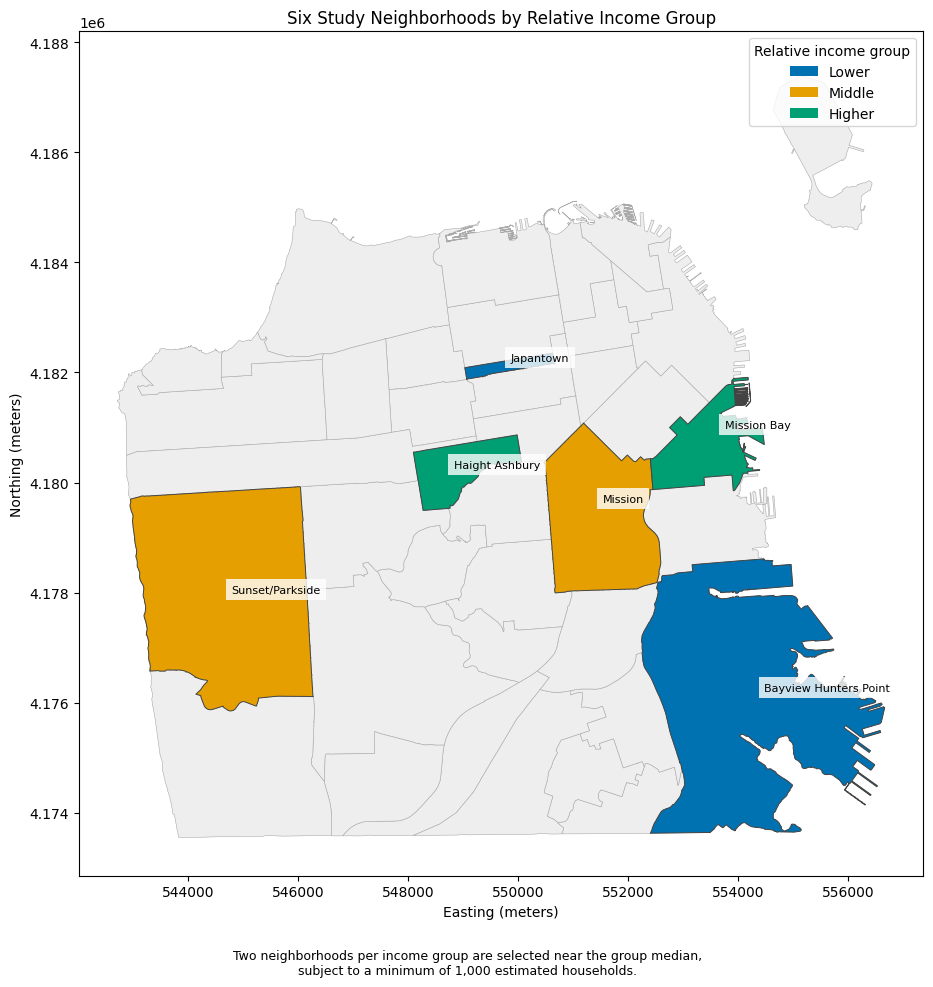

Study neighborhoods: 6
Saved: outputs/figures/selected_neighborhoods_income_groups.png


In [26]:
from matplotlib.patches import Patch

# Attach the selected neighborhoods' income information to their boundaries.
study_neighborhoods = neighborhoods_projected[
    ["nhood", "geometry"]
].merge(
    selected_neighborhoods,
    on="nhood",
    how="inner",
    validate="one_to_one"
)

# Use these colors consistently in subsequent maps and charts.
income_colors = {
    "Lower": "#0072B2",
    "Middle": "#E69F00",
    "Higher": "#009E73"
}

fig, ax = plt.subplots(figsize=(10, 10))

# Show all neighborhoods as geographic context.
neighborhoods_projected.plot(
    ax=ax,
    color="#eeeeee",
    edgecolor="#aaaaaa",
    linewidth=0.4
)

# Highlight the six selected neighborhoods by relative income group.
for band, color in income_colors.items():
    study_neighborhoods.loc[
        study_neighborhoods["income_band"].eq(band)
    ].plot(
        ax=ax,
        color=color,
        edgecolor="#444444",
        linewidth=0.7
    )

# Place labels inside each neighborhood where possible.
for _, row in study_neighborhoods.iterrows():
    point = row.geometry.representative_point()
    ax.annotate(
        row["nhood"],
        xy=(point.x, point.y),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
    )

ax.legend(
    handles=[
        Patch(facecolor=color, label=band)
        for band, color in income_colors.items()
    ],
    title="Relative income group"
)

ax.set_title("Six Study Neighborhoods by Relative Income Group")
ax.set_xlabel("Easting (meters)")
ax.set_ylabel("Northing (meters)")

fig.text(
    0.5, 0.02,
    "Two neighborhoods per income group are selected near the group median,\n"
    "subject to a minimum of 1,000 estimated households.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

# Save a report-ready copy using a relative output path.
figures_dir = Path("outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

map_file = figures_dir / "selected_neighborhoods_income_groups.png"
fig.savefig(map_file, dpi=300, bbox_inches="tight")

plt.show()
print("Study neighborhoods:", len(study_neighborhoods))
print("Saved:", map_file)

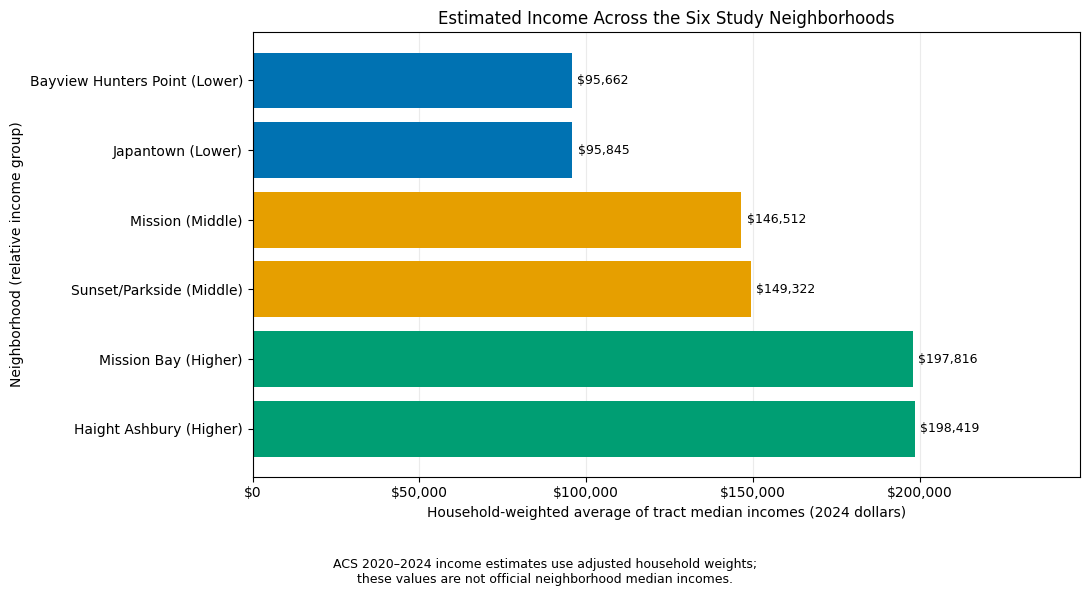

Saved: outputs/figures/selected_neighborhoods_income.png


In [30]:
from matplotlib.ticker import StrMethodFormatter

# Order the selected neighborhoods from lowest to highest income.
chart_data = selected_neighborhoods.sort_values(
    "estimated_income"
).copy()

labels = [
    f"{name} ({band})"
    for name, band in zip(chart_data["nhood"], chart_data["income_band"])
]
colors = [
    income_colors[band]
    for band in chart_data["income_band"]
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    labels,
    chart_data["estimated_income"],
    color=colors
)
ax.invert_yaxis()

# Label bars with estimated dollar values.
ax.bar_label(
    bars,
    labels=[
        f"${value:,.0f}"
        for value in chart_data["estimated_income"]
    ],
    padding=4,
    fontsize=9
)

# Leave space for labels and format the axis in dollars.
ax.set_xlim(0, chart_data["estimated_income"].max() * 1.25)
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

ax.set_title("Estimated Income Across the Six Study Neighborhoods")
ax.set_xlabel(
    "Household-weighted average of tract median incomes (2024 dollars)"
)
ax.set_ylabel("Neighborhood (relative income group)")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)

fig.text(
    0.5, 0.02,
    "ACS 2020–2024 income estimates use adjusted household weights;\n"
    "these values are not official neighborhood median incomes.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.10, 1, 1])

chart_file = figures_dir / "selected_neighborhoods_income.png"
fig.savefig(chart_file, dpi=300, bbox_inches="tight")

plt.show()
print("Saved:", chart_file)

In [27]:
def save_table(table, destination):
    """Save a table without its pandas index."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(destination, index=False)
    print(f"Saved {destination} ({len(table)} rows)")


# Save results and checks using relative project paths.
tables_dir = Path("outputs/tables")

tables_to_save = {
    "neighborhood_income_all_41.csv": income_table,
    "selected_neighborhoods.csv": selected_neighborhoods,
    "initial_selected_neighborhoods.csv": initial_selected_neighborhoods,
    "excluded_selection_candidates.csv": excluded_candidates,
    "income_allocation_comparison.csv": income_comparison,
    "acs_cleaning_log.csv": acs_cleaning_log,
    "tract_coverage_check.csv": tract_coverage
}

for filename, table in tables_to_save.items():
    save_table(table, tables_dir / filename)

# Keep the cleaned tract-level Census data separate from the raw source.
save_table(
    income_clean,
    Path("data/processed/acs_2024_sf_tracts_clean.csv")
)

Saved outputs/tables/neighborhood_income_all_41.csv (41 rows)
Saved outputs/tables/selected_neighborhoods.csv (6 rows)
Saved outputs/tables/initial_selected_neighborhoods.csv (6 rows)
Saved outputs/tables/excluded_selection_candidates.csv (5 rows)
Saved outputs/tables/income_allocation_comparison.csv (41 rows)
Saved outputs/tables/acs_cleaning_log.csv (4 rows)
Saved outputs/tables/tract_coverage_check.csv (244 rows)
Saved data/processed/acs_2024_sf_tracts_clean.csv (244 rows)


## Business destinations and opening hours

We will collect OpenStreetMap destinations in four categories:
grocery/convenience, pharmacy/health, food/drink, and general retail.
We include a half-mile buffer around each study neighborhood to capture
nearby destinations beyond its boundary.

We will inspect destination records and opening-hours completeness,
keeping missing hours classified as unknown. The buffer defines an
initial data collection area, not a 15-minute travel area; its extent
must be checked before drawing accessibility conclusions.

In [28]:
# Create search areas from the six selected neighborhood boundaries.
business_search_areas = study_neighborhoods[
    ["nhood", "income_band", "geometry"]
].copy()

# Buffer in the projected CRS, whose units are meters.
BUSINESS_BUFFER_METERS = 0.5 * 1609.344

business_search_areas["geometry"] = (
    business_search_areas.geometry.buffer(BUSINESS_BUFFER_METERS)
)

# Merge overlapping buffers into one combined query geometry.
combined_search_area = business_search_areas.geometry.union_all()

# OpenStreetMap queries require longitude/latitude coordinates.
business_query_polygon = (
    gpd.GeoSeries(
        [combined_search_area],
        crs=business_search_areas.crs
    )
    .to_crs(epsg=4326)
    .iloc[0]
)

print("Neighborhood search areas:", len(business_search_areas))
print("Buffer distance:", BUSINESS_BUFFER_METERS, "meters")
print("Combined query geometry:", business_query_polygon.geom_type)

display(business_search_areas[["nhood", "income_band"]])

Neighborhood search areas: 6
Buffer distance: 804.672 meters
Combined query geometry: MultiPolygon


,nhood,income_band
0,Sunset/Parkside,Middle
1,Mission Bay,Higher
2,Mission,Middle
3,Japantown,Lower
4,Haight Ashbury,Higher
5,Bayview Hunters Point,Lower


In [29]:
from time import perf_counter

# Show when the import starts so any delay is visible.
print("Loading OSMnx...", flush=True)
import_start = perf_counter()

import osmnx as ox

print(
    f"OSMnx {ox.__version__} loaded "
    f"in {perf_counter() - import_start:.1f} seconds."
)

# Reuse locally cached responses when repeating the same request.
ox.settings.use_cache = True
ox.settings.cache_folder = "data/raw/osmnx_cache"

# Display progress messages during data downloads.
ox.settings.log_console = True

# Set the HTTP request and Overpass query timeout in seconds.
ox.settings.requests_timeout = 180

print("OSMnx setup complete.")

Loading OSMnx...
OSMnx 2.0.7 loaded in 22.8 seconds.
OSMnx setup complete.


In [30]:
import json
from datetime import datetime, timezone

# Collect shops, food/drink destinations, and health facilities.
# These are candidates; category filtering and duplicate checks come next.
business_tags = {
    "shop": True,
    "amenity": [
        "restaurant", "cafe", "fast_food", "bar", "pub",
        "food_court", "ice_cream",
        "pharmacy", "clinic", "doctors", "dentist", "hospital"
    ],
    "healthcare": True
}

business_raw_file = raw_dir / "osm_business_candidates_raw.geojson"
business_metadata_file = raw_dir / "osm_business_query_metadata.json"

if business_raw_file.is_file():
    # Reuse the saved snapshot when rerunning this analysis.
    print("Using saved snapshot:", business_raw_file)
    businesses_raw = gpd.read_file(business_raw_file)

else:
    print("Requesting destination candidates from OpenStreetMap...", flush=True)

    downloaded_features = ox.features_from_polygon(
        business_query_polygon,
        tags=business_tags
    )

    # Preserve both parts of each feature's unique OpenStreetMap identity.
    businesses_raw = (
        downloaded_features
        .rename_axis(["osm_element", "osm_id"])
        .reset_index()
    )

    # Save all returned fields and geometries before cleaning.
    business_raw_file.write_text(
        businesses_raw.to_json(drop_id=True),
        encoding="utf-8"
    )

    # Record when, where, and how this snapshot was requested.
    metadata = {
        "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
        "source": "OpenStreetMap via OSMnx/Overpass",
        "osmnx_version": ox.__version__,
        "buffer_meters": BUSINESS_BUFFER_METERS,
        "neighborhoods": sorted(study_neighborhoods["nhood"].tolist()),
        "tags": business_tags,
        "query_crs": "EPSG:4326",
        "query_polygon_wkt": business_query_polygon.wkt
    }

    business_metadata_file.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    print("Saved:", business_raw_file)
    print("Saved:", business_metadata_file)

print("Raw destination candidate records:", len(businesses_raw))
print("CRS:", businesses_raw.crs)

# Display useful fields, even if a tag is absent from the entire response.
display(
    businesses_raw.reindex(columns=[
        "osm_element", "osm_id", "name", "shop",
        "amenity", "healthcare", "opening_hours", "geometry"
    ]).head(10)
)

Requesting destination candidates from OpenStreetMap...
Saved: data/raw/osm_business_candidates_raw.geojson
Saved: data/raw/osm_business_query_metadata.json
Raw destination candidate records: 4797
CRS: epsg:4326


,osm_element,osm_id,name,shop,amenity,healthcare,opening_hours,geometry
0,node,61670779,Woods Lowside,NaN,pub,NaN,"Su,Mo-We 13:00-22:00; Th 13:00-23:00; Fr-Sa 13...",POINT (-122.43102 37.77214)
1,node,61671096,Toronado,NaN,pub,NaN,11:00-02:00,POINT (-122.43122 37.77191)
2,node,61671382,Molotov's,NaN,pub,NaN,15:00-02:00,POINT (-122.43176 37.77205)
3,node,61672275,Noc Noc,NaN,pub,NaN,NaN,POINT (-122.43142 37.77189)
4,node,61673273,Danny Coyle's,NaN,pub,NaN,Mo 16:00-22:00; Tu 14:00-22:00; We-Fr 14:00-26...,POINT (-122.43326 37.77186)
5,node,61674029,The Page,NaN,pub,NaN,Mo-Th 16:00-02:00; Fr-Su 13:00-02:00,POINT (-122.43706 37.77212)
6,node,61675193,Martuni's,NaN,bar,NaN,NaN,POINT (-122.42277 37.77213)
7,node,61676294,The Green Heron,NaN,bar,NaN,NaN,POINT (-122.44871 37.76968)
8,node,61677300,Magnolia SF,NaN,pub,NaN,"Mo-Th,Su 12:00-24:00; Fr 12:00-01:00; Sa 11:00...",POINT (-122.44519 37.77034)
9,node,61677421,The Gold Cane,NaN,pub,NaN,NaN,POINT (-122.44801 37.76977)


In [31]:
# Identify missing or blank text without changing the raw data.
name_missing = (
    businesses_raw["name"]
    .astype("string")
    .fillna("")
    .str.strip()
    .eq("")
)

hours_missing = (
    businesses_raw["opening_hours"]
    .astype("string")
    .fillna("")
    .str.strip()
    .eq("")
)

# An OSM identity combines element type and ID.
# A node and a way can legitimately have the same numeric ID.
business_checks = pd.Series({
    "Raw candidate records": len(businesses_raw),
    "Missing OSM identifiers": (
        businesses_raw[["osm_element", "osm_id"]]
        .isna().any(axis=1).sum()
    ),
    "Duplicate OSM identity pairs": (
        businesses_raw.duplicated(
            subset=["osm_element", "osm_id"]
        ).sum()
    ),
    "Missing or blank names": name_missing.sum(),
    "Missing geometries": businesses_raw.geometry.isna().sum(),
    "Empty geometries": businesses_raw.geometry.is_empty.sum(),
    "Invalid nonmissing geometries": (
        businesses_raw.geometry.notna()
        & ~businesses_raw.geometry.is_valid
    ).sum(),
    "Missing or blank opening hours": hours_missing.sum(),
    "Opening hours provided, not yet validated": (~hours_missing).sum()
})

display(business_checks)

print("\nGeometry types:")
display(businesses_raw.geometry.geom_type.value_counts(dropna=False))

# Inspect actual tag values before defining category filters.
for column in ["shop", "amenity", "healthcare"]:
    print(f"\nMost common {column} values:")
    display(
        businesses_raw[column]
        .value_counts(dropna=False)
        .head(15)
    )

print("\nRows removed so far: 0")

Raw candidate records                        4797
Missing OSM identifiers                         0
Duplicate OSM identity pairs                    0
Missing or blank names                        212
Missing geometries                              0
Empty geometries                                0
Invalid nonmissing geometries                   0
Missing or blank opening hours               2911
Opening hours provided, not yet validated    1886
dtype: int64


Geometry types:


Point      4307
Polygon     490
Name: count, dtype: int64


Most common shop values:


shop
NaN             2188
hairdresser      228
convenience      201
clothes          178
beauty           172
car_repair       112
vacant           109
laundry           82
bakery            73
supermarket       72
dry_cleaning      70
alcohol           53
gift              51
massage           41
yes               40
Name: count, dtype: int64


Most common amenity values:


amenity
NaN               2667
restaurant         954
cafe               416
fast_food          235
bar                181
pub                 79
dentist             79
clinic              64
ice_cream           29
pharmacy            27
doctors             24
post_office         12
hospital            12
food_court           7
bicycle_rental       1
Name: count, dtype: int64


Most common healthcare values:


healthcare
NaN                 4493
dentist               79
clinic                67
alternative           43
pharmacy              26
doctor                22
hospital              12
yes                   10
physiotherapist       10
optometrist            9
laboratory             8
speech_therapist       5
dialysis               3
rehabilitation         2
counselling            1
Name: count, dtype: int64


Rows removed so far: 0


In [32]:
# Inspect all tag values before deciding category eligibility.
# This documents what the broad download actually contains.
for column in ["shop", "healthcare"]:
    tag_inventory = (
        businesses_raw[column]
        .dropna()
        .astype("string")
        .str.strip()
        .value_counts()
        .rename_axis(column)
        .reset_index(name="records")
    )

    print(f"\nComplete {column} inventory:")
    with pd.option_context("display.max_rows", None):
        display(tag_inventory)

# Identify available status fields for a later closure/access check.
status_columns = [
    column for column in businesses_raw.columns
    if column in ["disused", "abandoned", "demolished", "access"]
    or column.startswith(
        ("disused:", "abandoned:", "demolished:", "closed:")
    )
]

print("\nAvailable status fields:", status_columns)
print("Rows removed so far: 0")


Complete shop inventory:


,shop,records
0,hairdresser,228
1,convenience,201
2,clothes,178
3,beauty,172
4,car_repair,112
5,vacant,109
6,laundry,82
7,bakery,73
8,supermarket,72
9,dry_cleaning,70



Complete healthcare inventory:


,healthcare,records
0,dentist,79
1,clinic,67
2,alternative,43
3,pharmacy,26
4,doctor,22
5,hospital,12
6,yes,10
7,physiotherapist,10
8,optometrist,9
9,laboratory,8



Available status fields: ['disused:amenity', 'disused:website', 'disused:cuisine', 'disused:shop', 'disused:name', 'access', 'disused:clothes', 'disused:office', 'disused', 'disused:leisure']
Rows removed so far: 0


In [33]:
# Work on a separate table; keep businesses_raw unchanged.
businesses_work = businesses_raw.copy()


def split_osm_values(value):
    """Normalize case and whitespace, preserving semicolon-separated values."""
    if pd.isna(value):
        return []

    return sorted({
        part.strip().lower()
        for part in str(value).split(";")
        if part.strip()
    })


normalization_records = []

for column in ["shop", "amenity", "healthcare"]:
    original_text = (
        businesses_work[column].astype("string").fillna("")
    )
    normalized_text = original_text.str.strip().str.lower()

    # Helper columns allow classification using every listed value.
    token_column = f"{column}_tokens"
    businesses_work[token_column] = (
        businesses_work[column].map(split_osm_values)
    )

    normalization_records.append({
        "field": column,
        "case_or_whitespace_changes": int(
            original_text.ne(normalized_text).sum()
        ),
        "multi_value_records": int(
            businesses_work[token_column].map(len).gt(1).sum()
        )
    })

business_tag_normalization_log = pd.DataFrame(normalization_records)
display(business_tag_normalization_log)

# Inspect closure and access values before defining exclusion rules.
for column in ["disused", "disused:shop", "disused:amenity", "access"]:
    if column in businesses_work.columns:
        print(f"\n{column}:")
        display(
            businesses_work[column]
            .astype("string")
            .fillna("(missing)")
            .value_counts()
        )

print("\nRecords retained:", len(businesses_work))
print("Rows removed so far: 0")

,field,case_or_whitespace_changes,multi_value_records
0,shop,1,13
1,amenity,0,0
2,healthcare,0,1



disused:


disused
(missing)    4794
yes             3
Name: count, dtype: Int64


disused:shop:


disused:shop
(missing)    4793
yes             3
clothes         1
Name: count, dtype: Int64


disused:amenity:


disused:amenity
(missing)     4790
restaurant       5
cafe             2
Name: count, dtype: Int64


access:


access
(missing)      4794
customers         1
destination       1
private           1
Name: count, dtype: Int64


Records retained: 4797
Rows removed so far: 0


In [34]:
# Identify records needing review before a closure/access exclusion.
disused_flag = (
    businesses_work["disused"]
    .astype("string")
    .fillna("")
    .str.strip()
    .str.lower()
    .eq("yes")
)

restricted_access = (
    businesses_work["access"]
    .astype("string")
    .fillna("")
    .str.strip()
    .str.lower()
    .isin(["private", "no"])
)

status_review_mask = (
    disused_flag
    | businesses_work["disused:shop"].notna()
    | businesses_work["disused:amenity"].notna()
    | restricted_access
)

business_status_review = businesses_work.loc[
    status_review_mask
].copy()

print("Records requiring status review:", len(business_status_review))

# Compare current tags with historical/disused tags.
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(
        business_status_review[
            ["osm_element", "osm_id", "name",
             "shop", "amenity", "healthcare",
             "disused", "disused:shop", "disused:amenity", "access"]
        ]
    )

print("Rows removed so far: 0")

Records requiring status review: 15


,osm_element,osm_id,name,shop,amenity,healthcare,disused,disused:shop,disused:amenity,access
490,node,1975916973,DeliShack,NaN,cafe,NaN,NaN,NaN,restaurant,NaN
635,node,2321299157,Welcome Castro,gift,NaN,NaN,NaN,clothes,NaN,NaN
769,node,2657227481,Saap Ver,NaN,restaurant,NaN,NaN,NaN,restaurant,NaN
933,node,3397869806,Massage Envy,massage,NaN,NaN,NaN,yes,NaN,NaN
1092,node,3648576378,Los 3 Cachanillas,NaN,restaurant,NaN,NaN,NaN,restaurant,NaN
1281,node,4001273405,Oishii Matcha,NaN,cafe,NaN,NaN,NaN,cafe,NaN
1851,node,4615928118,Palmer's,NaN,bar,NaN,yes,NaN,NaN,NaN
2215,node,6171912808,Mandi House,NaN,restaurant,NaN,NaN,NaN,restaurant,NaN
3843,node,13343944685,NaN,vacant,NaN,NaN,yes,NaN,NaN,NaN
3844,node,13343944686,NaN,vacant,NaN,NaN,yes,NaN,NaN,NaN


Rows removed so far: 0


We exclude records explicitly tagged as disused, vacant, or restricted
to private/no access. Records with conflicting current and disused tags
are set aside for review rather than assumed open or closed.

A current business tag can remain eligible when its historical tag
describes a different use. Missing names and opening hours alone do not
exclude a destination. These decisions reflect the downloaded tags,
not independent verification of current business activity.

In [35]:
def assess_business_status(row):
    """Assign one status decision using explicit, ordered rules."""
    shop = set(row["shop_tokens"])
    amenity = set(row["amenity_tokens"])
    healthcare = set(row["healthcare_tokens"])

    # Whole-feature disuse takes priority over other tags.
    if "yes" in split_osm_values(row.get("disused")):
        return "Exclude: marked disused"

    if set(split_osm_values(row.get("access"))) & {"private", "no"}:
        return "Exclude: restricted access"

    # Review vacancy if another current tag suggests an operating venue.
    if "vacant" in shop:
        if (shop - {"vacant"}) or amenity or healthcare:
            return "Review: vacancy/current-tag conflict"
        return "Exclude: vacant premises"

    # A matching historical tag, or generic disused:shop=yes,
    # conflicts with the current tag and needs further review.
    for field in ["shop", "amenity"]:
        current = set(row[f"{field}_tokens"])
        former = set(split_osm_values(row.get(f"disused:{field}")))

        if current and ("yes" in former or current.intersection(former)):
            return "Review: current/disused-tag conflict"

    return "Retain for categorization"


# Keep decisions on the full table so every exclusion is traceable.
businesses_work["status_decision"] = businesses_work.apply(
    assess_business_status,
    axis=1
)

business_status_log = (
    businesses_work["status_decision"]
    .value_counts()
    .rename_axis("decision")
    .reset_index(name="records")
)

# Preserve excluded and uncertain records separately.
businesses_excluded = businesses_work.loc[
    businesses_work["status_decision"].str.startswith("Exclude:")
].copy()

businesses_needing_review = businesses_work.loc[
    businesses_work["status_decision"].str.startswith("Review:")
].copy()

businesses_eligible = businesses_work.loc[
    businesses_work["status_decision"].eq("Retain for categorization")
].copy()

display(business_status_log)

print("Original candidates:", len(businesses_work))
print("Excluded by status:", len(businesses_excluded))
print("Set aside for review:", len(businesses_needing_review))
print("Retained for categorization:", len(businesses_eligible))

,decision,records
0,Retain for categorization,4677
1,Exclude: vacant premises,105
2,Review: current/disused-tag conflict,9
3,Exclude: marked disused,3
4,Review: vacancy/current-tag conflict,2
5,Exclude: restricted access,1


Original candidates: 4797
Excluded by status: 109
Set aside for review: 11
Retained for categorization: 4677


We classify destinations as grocery/convenience, pharmacy/health,
food/drink, or general retail using explicit OpenStreetMap tag lists.

Grocery/convenience includes grocery stores and ingredient-focused food
shops. Food/drink includes prepared-food venues and specialty beverage
or sweet shops. Pharmacy/health includes health facilities and related
retailers. General retail covers other specified goods retailers;
personal, repair, and professional services fall outside these categories.

A destination may match multiple categories. It is counted once within
each matching category, so category totals should not be added together
as a count of unique destinations. Unmatched records remain under review.

In [37]:
# Explicit project definitions, based on the inspected tag inventory.
grocery_shops = set("""
supermarket convenience grocery greengrocer butcher seafood cheese
health_food frozen_food pasta spices farm
""".split())

food_drink_shops = set("""
bakery deli pastry confectionery chocolate coffee tea alcohol wine
""".split())

health_shops = set("""
chemist optician medical_supply hearing_aids herbalist supplements
""".split())

healthcare_types = set("""
yes pharmacy clinic doctor dentist hospital alternative physiotherapist
optometrist laboratory speech_therapist dialysis rehabilitation counselling
blood_donation psychotherapist podiatrist midwife hospice vaccination_centre
""".split())

general_retail_shops = set("""
clothes clothing shoes bag fashion_accessories boutique baby_goods
gift jewelry watches florist plants garden_centre
furniture interior_decoration houseware home_goods kitchen bed carpet
lighting tiles flooring bathroom_furnishing curtain window_blind doors windows
hardware doityourself paint building_supply building_materials electrical
electronics computer mobile_phone appliance hifi camera photo video
books stationery music musical_instrument records games video_games toys
sports outdoor bicycle skate kites
art antiques craft frame framing pottery collector coins
wool sewing fabric leather party candles religion
cosmetics perfumery beauty_supply hairdresser_supply janitorial_supply
pet tobacco cannabis erotic
car motorcycle boat car_parts tyres
second_hand charity department_store variety_store general
""".split())

category_rules = {
    "Grocery/convenience": {
        "shop": grocery_shops
    },
    "Pharmacy/health": {
        "shop": health_shops,
        "amenity": {"pharmacy", "clinic", "doctors", "dentist", "hospital"},
        "healthcare": healthcare_types
    },
    "Food/drink": {
        "shop": food_drink_shops,
        "amenity": {
            "restaurant", "cafe", "fast_food", "bar", "pub",
            "food_court", "ice_cream"
        }
    },
    "General retail": {
        "shop": general_retail_shops
    }
}

category_columns = {
    "Grocery/convenience": "is_grocery",
    "Pharmacy/health": "is_health",
    "Food/drink": "is_food_drink",
    "General retail": "is_general_retail"
}


def matches_category(row, rules):
    """Match any allowed value across the category's relevant tag fields."""
    return any(
        bool(set(row[f"{field}_tokens"]).intersection(allowed_values))
        for field, allowed_values in rules.items()
    )


businesses_classified = businesses_eligible.copy()

# Separate flags preserve destinations that serve multiple categories.
for category, rules in category_rules.items():
    businesses_classified[category_columns[category]] = (
        businesses_classified.apply(
            matches_category, axis=1, args=(rules,)
        )
    )

flag_columns = list(category_columns.values())
businesses_classified["category_count"] = (
    businesses_classified[flag_columns].sum(axis=1)
)

business_category_summary = pd.DataFrame({
    "category": list(category_columns),
    "candidate_records": [
        int(businesses_classified[column].sum())
        for column in flag_columns
    ]
})

unclassified_candidates = businesses_classified.loc[
    businesses_classified["category_count"].eq(0)
].copy()

display(business_category_summary)

print("Candidates assessed:", len(businesses_classified))
print(
    "Matching at least one category:",
    businesses_classified["category_count"].gt(0).sum()
)
print("Unmatched candidates:", len(unclassified_candidates))
print(
    "Matching multiple categories:",
    businesses_classified["category_count"].gt(1).sum()
)

,category,candidate_records
0,Grocery/convenience,323
1,Pharmacy/health,354
2,Food/drink,2079
3,General retail,974


Candidates assessed: 4677
Matching at least one category: 3726
Unmatched candidates: 951
Matching multiple categories: 4


In [38]:
# Group unmatched records by their original tags.
# This distinguishes out-of-scope services from ambiguous or missed tags.
unmatched_tag_summary = (
    unclassified_candidates
    .groupby(["shop", "amenity", "healthcare"], dropna=False)
    .size()
    .reset_index(name="records")
    .sort_values("records", ascending=False)
    .reset_index(drop=True)
)

print("Unmatched candidate tag combinations:")
with pd.option_context("display.max_rows", None):
    display(unmatched_tag_summary)

print(
    "Unmatched records accounted for:",
    unmatched_tag_summary["records"].sum()
)

# Inspect records assigned to more than one category.
multiple_category_candidates = businesses_classified.loc[
    businesses_classified["category_count"].gt(1)
].copy()

print("\nCandidates matching multiple categories:")
with pd.option_context("display.max_columns", None):
    display(
        multiple_category_candidates[
            ["osm_element", "osm_id", "name",
             "shop", "amenity", "healthcare"]
            + flag_columns
        ]
    )

Unmatched candidate tag combinations:


,shop,amenity,healthcare,records
0,hairdresser,NaN,NaN,228
1,beauty,NaN,NaN,171
2,car_repair,NaN,NaN,112
3,laundry,NaN,NaN,82
4,dry_cleaning,NaN,NaN,70
5,massage,NaN,NaN,39
6,yes,NaN,NaN,38
7,tattoo,NaN,NaN,36
8,storage_rental,NaN,NaN,21
9,copyshop,NaN,NaN,18


Unmatched records accounted for: 951

Candidates matching multiple categories:


,osm_element,osm_id,name,shop,amenity,healthcare,is_grocery,is_health,is_food_drink,is_general_retail
1009,node,3562957694,Dragon Lounge,mobile_phone,bar,NaN,False,False,True,True
1164,node,3789688057,café suspiro,music,cafe,NaN,False,False,True,True
2132,node,5538811238,Le Marché Cezanne,convenience,cafe,NaN,True,False,True,False
2277,node,6471124720,Perfectly Seasoned,spices;tea,NaN,NaN,True,False,True,False


In [39]:
# Services outside the four categories defined for this project.
out_of_scope_services = set("""
hairdresser beauty car_repair laundry dry_cleaning massage tattoo
storage_rental copyshop pet_grooming tailor travel_agency rental ticket
psychic locksmith motorcycle_repair money_lender estate_agent pawnbroker
plant_hire printing funeral_directors spa mailing_company shoe_repair
shipping glaziery plumbers lottery
""".split())


def assess_unmatched_scope(row):
    """Separate known scope exclusions from uncertain classifications."""
    shop_values = set(row["shop_tokens"])

    # Require every listed shop value to be a recognized service.
    # Mixed or unfamiliar values remain available for review.
    if shop_values and shop_values.issubset(out_of_scope_services):
        return "Exclude: services outside project categories"

    if shop_values == {"mall"}:
        return "Exclude: aggregate shopping centre"

    return "Review: unspecified or unmapped category"


unclassified_candidates["scope_decision"] = (
    unclassified_candidates.apply(assess_unmatched_scope, axis=1)
)

business_scope_log = (
    unclassified_candidates["scope_decision"]
    .value_counts()
    .rename_axis("decision")
    .reset_index(name="records")
)

scope_exclusions = unclassified_candidates.loc[
    unclassified_candidates["scope_decision"].str.startswith("Exclude:")
].copy()

category_review_candidates = unclassified_candidates.loc[
    unclassified_candidates["scope_decision"].str.startswith("Review:")
].copy()

display(business_scope_log)
print("Unmatched records accounted for:", business_scope_log["records"].sum())

# Inspect a few potentially classifiable tags and the four overlaps.
review_shop_values = {
    "anime", "apparel and gifts", "embroidery", "telecommunication"
}

detail_mask = category_review_candidates["shop_tokens"].map(
    lambda values: bool(set(values).intersection(review_shop_values))
)

classification_review_details = pd.concat([
    category_review_candidates.loc[detail_mask],
    multiple_category_candidates
])

print("\nClassification cases requiring closer inspection:")
with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", None
):
    display(
        classification_review_details.reindex(columns=[
            "osm_element", "osm_id", "name", "shop", "amenity",
            "website", "contact:website"
        ])
    )

,decision,records
0,Exclude: services outside project categories,869
1,Review: unspecified or unmapped category,73
2,Exclude: aggregate shopping centre,9


Unmatched records accounted for: 951

Classification cases requiring closer inspection:


,osm_element,osm_id,name,shop,amenity,website,contact:website
818,node,2880720358,Picnic,apparel and gifts,NaN,NaN,NaN
2865,node,9934759413,Bubble Sort Studios,anime,NaN,https://shop.bubblesort.io/pages/visit-in-person,NaN
3093,node,10575364930,Xfinity,telecommunication,NaN,NaN,NaN
4152,node,13836741079,Bay Custom,embroidery,NaN,https://baycustomsf.com/,NaN
1009,node,3562957694,Dragon Lounge,mobile_phone,bar,NaN,NaN
1164,node,3789688057,café suspiro,music,cafe,https://cafesuspiro.com/,NaN
2132,node,5538811238,Le Marché Cezanne,convenience,cafe,https://www.lemarchecezanne.com/,NaN
2277,node,6471124720,Perfectly Seasoned,spices;tea,NaN,https://www.perfectlyseasonedsf.com/,NaN


In [40]:
# Record case-specific decisions without changing the original OSM tags.
manual_category_review_log = pd.DataFrame([
    (
        "node", 2880720358, "Add general retail",
        "https://www.picnicsf.com/",
        "Apparel/gifts tag and website support goods retail."
    ),
    (
        "node", 9934759413, "Add general retail",
        "https://shop.bubblesort.io/pages/visit-in-person",
        "Website identifies a physical shop selling zines and other goods."
    ),
    (
        "node", 10575364930, "Add general retail",
        "https://www.xfinity.com/local/ca/san-francisco",
        "Company SF store pages support retail; point address not verified."
    ),
    (
        "node", 13836741079, "Add general retail",
        "https://baycustomsf.com/shop/",
        "Website confirms hats available for purchase in the physical shop."
    ),
    (
        "node", 3562957694, "Hold for review",
        "",
        "Conflicting bar/mobile-phone tags; classification unresolved."
    )
], columns=[
    "osm_element", "osm_id", "decision", "source_url", "reason"
])

# Keep the actual review date fixed when rerunning the notebook.
manual_category_review_log["review_date"] = "2026-10-26"

businesses_reviewed = businesses_classified.copy()
businesses_reviewed["manual_review_pending"] = False

for review in manual_category_review_log.itertuples(index=False):
    match = (
        businesses_reviewed["osm_element"].eq(review.osm_element)
        & businesses_reviewed["osm_id"].eq(review.osm_id)
    )

    # Stop rather than silently applying a decision to an unexpected dataset.
    if match.sum() != 1:
        raise ValueError(
            f"Expected one record for {review.osm_element}/{review.osm_id}"
        )

    if review.decision == "Add general retail":
        businesses_reviewed.loc[match, "is_general_retail"] = True
    else:
        businesses_reviewed.loc[match, "manual_review_pending"] = True

# Recalculate category membership after the documented adjustments.
businesses_reviewed["category_count"] = (
    businesses_reviewed[flag_columns].sum(axis=1)
)

# Retain classified candidates without unresolved classification conflicts.
businesses_in_scope = businesses_reviewed.loc[
    businesses_reviewed["category_count"].gt(0)
    & ~businesses_reviewed["manual_review_pending"]
].copy()

business_category_summary_reviewed = pd.DataFrame({
    "category": list(category_columns),
    "candidate_records": [
        int(businesses_in_scope[column].sum())
        for column in flag_columns
    ]
})

display(manual_category_review_log)
display(business_category_summary_reviewed)

print("In-scope candidate records:", len(businesses_in_scope))
print(
    "Candidates matching multiple categories:",
    businesses_in_scope["category_count"].gt(1).sum()
)

,osm_element,osm_id,decision,source_url,reason,review_date
0,node,2880720358,Add general retail,https://www.picnicsf.com/,Apparel/gifts tag and website support goods re...,2026-10-26
1,node,9934759413,Add general retail,https://shop.bubblesort.io/pages/visit-in-person,Website identifies a physical shop selling zin...,2026-10-26
2,node,10575364930,Add general retail,https://www.xfinity.com/local/ca/san-francisco,Company SF store pages support retail; point a...,2026-10-26
3,node,13836741079,Add general retail,https://baycustomsf.com/shop/,Website confirms hats available for purchase i...,2026-10-26
4,node,3562957694,Hold for review,,Conflicting bar/mobile-phone tags; classificat...,2026-10-26


,category,candidate_records
0,Grocery/convenience,323
1,Pharmacy/health,354
2,Food/drink,2078
3,General retail,977


In-scope candidate records: 3729
Candidates matching multiple categories: 3


We excluded the Dragon Lounge record (OSM node 3562957694) from the
primary analysis because it was tagged as both a bar and a mobile-phone
shop, and we could not resolve that classification conflict. The record
remains in the raw data and review log to document the exclusion.

We screen for possible duplicate establishments using matching normalized
names and geometries within 25 meters in EPSG:26910. The distance is a
review threshold, not an automatic deletion rule.

This can identify a business mapped as both a point and a polygon.
It can miss duplicates with different or missing names, so it is an
initial check rather than proof that all establishments are unique.

In [41]:
import re
import unicodedata


def normalize_business_name(value):
    """Ignore case, accents, spacing, and punctuation for duplicate screening."""
    if pd.isna(value):
        return ""

    text = unicodedata.normalize("NFKD", str(value)).casefold()
    text = "".join(
        character for character in text
        if not unicodedata.combining(character)
    )
    return re.sub(r"[\W_]+", "", text)


# Use meters for distance comparisons; preserve the original geometries.
businesses_projected = businesses_in_scope.to_crs(epsg=26910).copy()

businesses_projected["osm_key"] = (
    businesses_projected["osm_element"].astype(str)
    + "/"
    + businesses_projected["osm_id"].astype(str)
)

businesses_projected["name_key"] = (
    businesses_projected["name"].map(normalize_business_name)
)
businesses_projected["geometry_type"] = (
    businesses_projected.geometry.geom_type
)

# Exclude blank names from this particular matching screen.
named_candidates = businesses_projected.loc[
    businesses_projected["name_key"].ne(""),
    ["osm_key", "name", "name_key", "geometry_type", "geometry"]
].reset_index(drop=True)

DUPLICATE_REVIEW_METERS = 25

nearby_pairs = gpd.sjoin(
    named_candidates,
    named_candidates,
    how="inner",
    predicate="dwithin",
    distance=DUPLICATE_REVIEW_METERS,
    lsuffix="left",
    rsuffix="right"
)

# Remove self-matches and retain each pair only once.
# Then require matching normalized names.
possible_duplicates = nearby_pairs.loc[
    (
        nearby_pairs["osm_key_left"]
        < nearby_pairs["osm_key_right"]
    )
    & (
        nearby_pairs["name_key_left"]
        == nearby_pairs["name_key_right"]
    )
].copy()

# Measure minimum distance between the original geometries.
# A point inside a polygon has a geometric distance of zero.
possible_duplicates["distance_m"] = [
    geometry.distance(
        named_candidates.loc[right_index, "geometry"]
    )
    for geometry, right_index in zip(
        possible_duplicates.geometry,
        possible_duplicates["index_right"]
    )
]

duplicate_candidate_pairs = (
    possible_duplicates[
        ["osm_key_left", "name_left", "geometry_type_left",
         "osm_key_right", "name_right", "geometry_type_right",
         "distance_m"]
    ]
    .sort_values(["distance_m", "name_left"])
    .reset_index(drop=True)
)

# Save the complete review table, including when no pairs are found.
review_file = Path("outputs/tables/duplicate_candidate_pairs.csv")
review_file.parent.mkdir(parents=True, exist_ok=True)
duplicate_candidate_pairs.to_csv(review_file, index=False)

print("In-scope candidate records:", len(businesses_projected))
print("Possible duplicate pairs:", len(duplicate_candidate_pairs))
print("Records removed by this check: 0")
print("Saved:", review_file)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(duplicate_candidate_pairs.round({"distance_m": 2}))

In-scope candidate records: 3729
Possible duplicate pairs: 12
Records removed by this check: 0
Saved: outputs/tables/duplicate_candidate_pairs.csv


,osm_key_left,name_left,geometry_type_left,osm_key_right,name_right,geometry_type_right,distance_m
0,way/222862959,Cliff's Variety,Polygon,way/222862962,Cliff's Variety,Polygon,0.00
1,node/5595082426,The Market,Point,way/1105289817,The Market,Polygon,0.00
2,way/263490215,Urgently Ortho,Polygon,way/263490226,Urgently Ortho,Polygon,0.00
3,node/1713269565,Walgreens,Point,way/194906345,Walgreens,Polygon,0.00
4,node/12676663498,Woods Outbound,Point,node/5876905615,Woods Outbound,Point,0.49
5,node/11061858559,CVS Pharmacy,Point,node/2718062345,CVS Pharmacy,Point,1.93
6,node/4017234514,Pineapple King Bakery,Point,node/4017234698,Pineapple King Bakery,Point,4.20
7,node/3622501400,West Pawtal Pet Supplies,Point,node/3622501504,West Pawtal Pet Supplies,Point,4.23
8,node/11226192570,Walgreens,Point,node/459506892,Walgreens,Point,4.47
9,node/3996578780,Physiotherapy Associates,Point,node/5061064108,Physiotherapy Associates,Point,16.86


In [42]:
# Assign a review number to each possible duplicate pair.
pair_list = duplicate_candidate_pairs.copy()
pair_list["pair_id"] = range(1, len(pair_list) + 1)

# Put both members of each pair into a single review table.
pair_members = pd.concat([
    pair_list[["pair_id", "osm_key_left"]]
        .rename(columns={"osm_key_left": "osm_key"})
        .assign(side="left"),
    pair_list[["pair_id", "osm_key_right"]]
        .rename(columns={"osm_key_right": "osm_key"})
        .assign(side="right")
], ignore_index=True)

review_columns = [
    "osm_key", "name", "geometry_type",
    "shop", "amenity", "healthcare",
    "addr:housenumber", "addr:street", "addr:unit", "addr:full",
    "phone", "contact:phone", "website", "contact:website",
    "opening_hours"
]

# Preserve missing fields as missing rather than inferring their values.
duplicate_review_details = pair_members.merge(
    businesses_projected.reindex(columns=review_columns),
    on="osm_key",
    how="left",
    validate="many_to_one"
).sort_values(["pair_id", "side"])

# Save complete details for documenting the eventual decisions.
detail_file = Path("outputs/tables/duplicate_review_details.csv")
duplicate_review_details.to_csv(detail_file, index=False)

print("Pairs under review:", len(pair_list))
print("Pair-member rows:", len(duplicate_review_details))
print("Records removed: 0")
print("Saved:", detail_file)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", None
):
    display(duplicate_review_details)

Pairs under review: 12
Pair-member rows: 24
Records removed: 0
Saved: outputs/tables/duplicate_review_details.csv


,pair_id,osm_key,side,name,geometry_type,shop,amenity,healthcare,addr:housenumber,addr:street,addr:unit,addr:full,phone,contact:phone,website,contact:website,opening_hours
0,1,way/222862959,left,Cliff's Variety,Polygon,gift,NaN,NaN,471,Castro Street,NaN,NaN,+1 415-431-5365,NaN,https://www.cliffsvariety.com/,NaN,Mo-Sa 10:00-18:30; Su 10:00-18:00
12,1,way/222862962,right,Cliff's Variety,Polygon,general,NaN,NaN,479,Castro Street,NaN,NaN,+1 415-431-5365,NaN,https://www.cliffsvariety.com/,NaN,Mo-Sa 10:00-18:30; Su 10:00-18:00
1,2,node/5595082426,left,The Market,Point,NaN,food_court,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://visitthemarket.com/,NaN,Mo-Fr 08:00-20:00
13,2,way/1105289817,right,The Market,Polygon,NaN,food_court,NaN,1355,Market Street,100,NaN,+1 415-767-5130,NaN,https://www.visitthemarket.com/,NaN,Mo-Th 11:00-19:00; Fr 11:00-18:30; Sa-Su off
2,3,way/263490215,left,Urgently Ortho,Polygon,NaN,doctors,doctor,2205,Post Street,NaN,NaN,NaN,NaN,NaN,NaN,Mo-Fr 10:00-18:00
14,3,way/263490226,right,Urgently Ortho,Polygon,NaN,NaN,doctor,2215,Post Street,NaN,NaN,+1 415-390-6511,NaN,https://urgentlyortho.com/,NaN,Mo-Fr 10:00-18:00
3,4,node/1713269565,left,Walgreens,Point,NaN,pharmacy,pharmacy,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,4,way/194906345,right,Walgreens,Polygon,chemist,NaN,NaN,1333,Castro Street,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,node/12676663498,left,Woods Outbound,Point,NaN,pub,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,5,node/5876905615,right,Woods Outbound,Point,NaN,bar,NaN,4045,Judah Street,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [43]:
# Record what the duplicate-review table supports.
# "Proposed merge" is an analysis decision, not external verification.
review_decisions = pd.DataFrame(
    [
        (1, "Review address",
         "Same contact details, but different street numbers and shop tags."),
        (2, "Review hours",
         "Matching name and website with overlapping geometry, but conflicting hours."),
        (3, "Review address",
         "Adjacent polygons have different street numbers."),
        (4, "Proposed merge",
         "Same-name pharmacy point overlaps the same-name store polygon; both hours missing."),
        (5, "Proposed merge",
         "Same name, locations less than one meter apart, and compatible bar/pub tags."),
        (6, "Review hours",
         "Same address and phone; store hours differ from pharmacy service hours."),
        (7, "Review address",
         "Same name and nearby locations, but different street numbers."),
        (8, "Review address",
         "Same name and nearby locations, but different street numbers."),
        (9, "Review hours",
         "Same address and phone; store hours differ from pharmacy service hours."),
        (10, "Proposed merge",
         "Same name, full street address, and healthcare type."),
        (11, "Review address",
         "Same name, but different street numbers."),
        (12, "Keep separate for now",
         "Website links identify different floors; proximity alone does not establish duplication.")
    ],
    columns=["pair_id", "review_decision", "reason"]
)

# Attach both OSM identifiers so decisions remain traceable.
duplicate_review_log = pair_list[
    ["pair_id", "osm_key_left", "osm_key_right"]
].merge(
    review_decisions,
    on="pair_id",
    how="left",
    validate="one_to_one"
)

assert duplicate_review_log["review_decision"].notna().all()

# Save the review record before changing the candidate dataset.
review_log_file = Path("outputs/tables/duplicate_review_log.csv")
review_log_file.parent.mkdir(parents=True, exist_ok=True)
duplicate_review_log.to_csv(review_log_file, index=False)

display(duplicate_review_log)
print("\nReview decisions:")
print(duplicate_review_log["review_decision"].value_counts())
print("\nRecords removed at this step: 0")
print("Saved:", review_log_file)

,pair_id,osm_key_left,osm_key_right,review_decision,reason
0,1,way/222862959,way/222862962,Review address,"Same contact details, but different street num..."
1,2,node/5595082426,way/1105289817,Review hours,Matching name and website with overlapping geo...
2,3,way/263490215,way/263490226,Review address,Adjacent polygons have different street numbers.
3,4,node/1713269565,way/194906345,Proposed merge,Same-name pharmacy point overlaps the same-nam...
4,5,node/12676663498,node/5876905615,Proposed merge,"Same name, locations less than one meter apart..."
5,6,node/11061858559,node/2718062345,Review hours,Same address and phone; store hours differ fro...
6,7,node/4017234514,node/4017234698,Review address,"Same name and nearby locations, but different ..."
7,8,node/3622501400,node/3622501504,Review address,"Same name and nearby locations, but different ..."
8,9,node/11226192570,node/459506892,Review hours,Same address and phone; store hours differ fro...
9,10,node/3996578780,node/5061064108,Proposed merge,"Same name, full street address, and healthcare..."



Review decisions:
review_decision
Review address           5
Review hours             3
Proposed merge           3
Keep separate for now    1
Name: count, dtype: int64

Records removed at this step: 0
Saved: outputs/tables/duplicate_review_log.csv


In [44]:
# Identify pairs with unresolved address or opening-hours questions.
unresolved_pairs = duplicate_review_log.loc[
    duplicate_review_log["review_decision"].isin(
        ["Review address", "Review hours"]
    )
].copy()

# List both OSM records belonging to each unresolved pair.
unresolved_members = pd.concat(
    [
        unresolved_pairs[
            ["pair_id", "osm_key_left", "review_decision", "reason"]
        ].rename(columns={"osm_key_left": "osm_key"}),

        unresolved_pairs[
            ["pair_id", "osm_key_right", "review_decision", "reason"]
        ].rename(columns={"osm_key_right": "osm_key"})
    ],
    ignore_index=True
)

# Ensure each excluded record has one review decision.
assert unresolved_members["osm_key"].is_unique

# Save identifying information and the reason for exclusion.
uncertain_duplicate_exclusions = unresolved_members.merge(
    businesses_projected[["osm_key", "name"]],
    on="osm_key",
    how="left",
    validate="one_to_one"
)

uncertain_duplicate_exclusions.to_csv(
    "outputs/tables/unresolved_duplicate_exclusions.csv",
    index=False
)

# Create a new working dataset; preserve the original candidates.
businesses_after_duplicate_review = businesses_projected.loc[
    ~businesses_projected["osm_key"].isin(
        unresolved_members["osm_key"]
    )
].copy()

print("Unresolved pairs excluded:", len(unresolved_pairs))
print("Candidate records excluded:", len(uncertain_duplicate_exclusions))
print("Candidate records remaining:", len(businesses_after_duplicate_review))
print("The three proposed merges have not been applied yet.")

Unresolved pairs excluded: 8
Candidate records excluded: 16
Candidate records remaining: 3713
The three proposed merges have not been applied yet.


In [45]:
# Specify which representation to retain for each duplicate pair.
duplicate_merge_log = pd.DataFrame(
    [
        (
            "way/194906345",
            "node/1713269565",
            "Retain the Walgreens polygon with its street address."
        ),
        (
            "node/5876905615",
            "node/12676663498",
            "Retain the Woods Outbound point with its street address."
        ),
        (
            "node/3996578780",
            "node/5061064108",
            "Same name, address, and healthcare type; retain the lower OSM ID."
        )
    ],
    columns=["keep_osm_key", "remove_osm_key", "reason"]
)

# Work on a copy so earlier cleaning steps remain reproducible.
businesses_deduplicated = (
    businesses_after_duplicate_review.copy()
    .set_index("osm_key", drop=False)
)

assert businesses_deduplicated.index.is_unique

# Preserve the source identifiers behind each retained destination.
businesses_deduplicated["source_osm_keys"] = (
    businesses_deduplicated["osm_key"]
)

for merge in duplicate_merge_log.itertuples(index=False):
    source_keys = [merge.keep_osm_key, merge.remove_osm_key]

    assert all(
        key in businesses_deduplicated.index
        for key in source_keys
    )

    # Confirm that neither source has hours that could be lost.
    source_hours = businesses_deduplicated.loc[
        source_keys, "opening_hours"
    ]
    assert source_hours.fillna("").astype(str).str.strip().eq("").all()

    # Preserve every category supported by either representation.
    combined_categories = businesses_deduplicated.loc[
        source_keys, flag_columns
    ].any(axis=0)

    for column in flag_columns:
        businesses_deduplicated.loc[
            merge.keep_osm_key, column
        ] = bool(combined_categories[column])

    businesses_deduplicated.loc[
        merge.keep_osm_key, "source_osm_keys"
    ] = ";".join(source_keys)

    businesses_deduplicated = businesses_deduplicated.drop(
        index=merge.remove_osm_key
    )

# Refresh category counts after merging.
businesses_deduplicated["category_count"] = (
    businesses_deduplicated[flag_columns].sum(axis=1)
)
businesses_deduplicated = businesses_deduplicated.reset_index(drop=True)

duplicate_merge_log.to_csv(
    "outputs/tables/applied_duplicate_merges.csv",
    index=False
)

print("Records before merging:", len(businesses_after_duplicate_review))
print("Duplicate representations removed:", len(duplicate_merge_log))
print("Destination candidates remaining:", len(businesses_deduplicated))
display(duplicate_merge_log)

Records before merging: 3713
Duplicate representations removed: 3
Destination candidates remaining: 3710


,keep_osm_key,remove_osm_key,reason
0,way/194906345,node/1713269565,Retain the Walgreens polygon with its street a...
1,node/5876905615,node/12676663498,Retain the Woods Outbound point with its stree...
2,node/3996578780,node/5061064108,"Same name, address, and healthcare type; retai..."


We excluded 16 records belonging to eight unresolved duplicate pairs from the primary analysis, while preserving their identifiers and exclusion reasons. We combined three additional pairs based on matching names, locations, and supporting attributes, retaining both source identifiers. We retained the two Maido records because their website links indicated different floors. This screening does not guarantee that every remaining record represents a distinct establishment.

### Locating destinations within neighborhood search areas

We represent each destination as a point. For polygon features, we use an interior representative point, which approximates its location rather than its entrance. We spatially join these points to the six neighborhood boundaries buffered by half a mile. These search areas describe nearby destinations; they do not establish 15-minute travel accessibility.

We use a spatial join (`gpd.sjoin`, predicate=`intersects`) to associate destination points with the half-mile-buffered neighborhood search areas in EPSG:26910. This join determines the destinations included in each area's category counts and recorded opening-hours summaries. Destinations can belong to multiple overlapping search areas.

In [47]:
# Use the projected CRS so spatial calculations use meters.
assert businesses_deduplicated.crs.to_epsg() == 26910

business_points = businesses_deduplicated.copy()

# Preserve the original geometry type for documentation.
business_points["source_geometry_type"] = (
    business_points.geometry.geom_type
)

# Existing points stay in place.
# Polygons become representative points inside their geometry.
business_points["geometry"] = (
    business_points.geometry.representative_point()
)

# Give search-area fields explicit names to distinguish them
# from a destination's actual neighborhood.
search_areas_for_join = business_search_areas[
    ["nhood", "income_band", "geometry"]
].rename(columns={
    "nhood": "search_neighborhood",
    "income_band": "search_income_band"
})

# A destination may match multiple overlapping search areas.
# A left join also retains destinations that match no search area.
business_search_matches = gpd.sjoin(
    business_points,
    search_areas_for_join,
    how="left",
    predicate="intersects"
)

matched_mask = (
    business_search_matches["search_neighborhood"].notna()
)

print("Destination points:", len(business_points))
print(
    "Distinct destinations inside at least one search area:",
    business_search_matches.loc[
        matched_mask, "osm_key"
    ].nunique()
)
print(
    "Destinations outside all search areas:",
    business_search_matches.loc[
        ~matched_mask, "osm_key"
    ].nunique()
)

print("\nDistinct destinations per neighborhood search area:")
display(
    business_search_matches.loc[matched_mask]
    .groupby("search_neighborhood")["osm_key"]
    .nunique()
    .rename("destination_count")
    .sort_values(ascending=False)
)

Destination points: 3710
Distinct destinations inside at least one search area: 3709
Destinations outside all search areas: 1

Distinct destinations per neighborhood search area:


search_neighborhood
Mission                  1740
Japantown                 688
Haight Ashbury            584
Sunset/Parkside           573
Mission Bay               540
Bayview Hunters Point     281
Name: destination_count, dtype: int64

In [48]:
# Identify destinations whose representative points fall outside
# every buffered neighborhood search area.
outside_keys = business_search_matches.loc[
    business_search_matches["search_neighborhood"].isna(),
    "osm_key"
].unique()

outside_search_area_review = business_points.loc[
    business_points["osm_key"].isin(outside_keys)
].copy()

# Measure how far each point lies from the combined search area.
combined_buffer_geometry = business_search_areas.geometry.union_all()

outside_search_area_review["distance_to_search_area_m"] = (
    outside_search_area_review.geometry.distance(
        combined_buffer_geometry
    )
)

review_columns = [
    "osm_key", "name", "shop", "amenity", "healthcare",
    "source_geometry_type", "distance_to_search_area_m"
]

display(
    outside_search_area_review[review_columns].round(2)
)

# Save the review details without changing the destination dataset.
outside_search_area_review[review_columns].to_csv(
    "outputs/tables/destinations_outside_search_areas.csv",
    index=False
)

print("Records removed at this step: 0")

,osm_key,name,shop,amenity,healthcare,source_geometry_type,distance_to_search_area_m
3402,way/213590059,Proposition Chicken,NaN,restaurant,NaN,Polygon,12.11


Records removed at this step: 0


In [49]:
# Retain destinations whose representative points fall within
# at least one neighborhood search area.
business_points_in_search = business_points.loc[
    ~business_points["osm_key"].isin(outside_keys)
].copy()

# Keep only matched destination–search-area relationships.
# Destinations may appear in multiple neighborhood search areas.
business_search_matches_clean = business_search_matches.loc[
    business_search_matches["search_neighborhood"].notna()
].copy()

# Record why this boundary case was excluded.
boundary_exclusion_log = outside_search_area_review[
    ["osm_key", "name", "source_geometry_type",
     "distance_to_search_area_m"]
].copy()

boundary_exclusion_log["exclusion_reason"] = (
    "Representative point outside all buffered neighborhood search areas."
)

boundary_exclusion_log.to_csv(
    "outputs/tables/business_boundary_exclusions.csv",
    index=False
)

assert (
    business_search_matches_clean["osm_key"].nunique()
    == len(business_points_in_search)
)

print("Destination candidates before boundary filtering:", len(business_points))
print("Excluded by point-location rule:", len(boundary_exclusion_log))
print("Distinct destinations retained:", len(business_points_in_search))

Destination candidates before boundary filtering: 3710
Excluded by point-location rule: 1
Distinct destinations retained: 3709


One restaurant polygon was returned by the original geometry query, but its representative point lay 12.11 meters outside all search areas. We excluded it from search-area summaries using the same point-location rule applied to every destination, while preserving its source record and exclusion reason.

In [50]:
# Count distinct destinations in each category and search area.
# A destination can contribute to multiple categories.
category_counts = pd.DataFrame({
    category: (
        business_search_matches_clean.loc[
            business_search_matches_clean[flag_column]
        ]
        .groupby("search_neighborhood")["osm_key"]
        .nunique()
    )
    for category, flag_column in category_columns.items()
}).fillna(0).astype(int)

# Include all six search areas, even if a category has no matches.
category_counts = category_counts.reindex(
    business_search_areas["nhood"],
    fill_value=0
)
category_counts.index.name = "search_neighborhood"

# Add income groups and overall distinct destination counts.
search_area_summary = (
    business_search_areas[["nhood", "income_band"]]
    .rename(columns={"nhood": "search_neighborhood"})
    .merge(
        category_counts.reset_index(),
        on="search_neighborhood",
        how="left",
        validate="one_to_one"
    )
)

total_counts = (
    business_search_matches_clean
    .groupby("search_neighborhood")["osm_key"]
    .nunique()
)

search_area_summary["total_distinct_destinations"] = (
    search_area_summary["search_neighborhood"].map(total_counts)
)

search_area_summary = search_area_summary.sort_values(
    ["income_band", "search_neighborhood"]
).reset_index(drop=True)

search_area_summary.to_csv(
    "outputs/tables/destination_counts_by_search_area.csv",
    index=False
)

display(search_area_summary)

,search_neighborhood,income_band,Grocery/convenience,Pharmacy/health,Food/drink,General retail,total_distinct_destinations
0,Bayview Hunters Point,Lower,48,12,161,60,281
1,Japantown,Lower,55,66,390,177,688
2,Mission,Middle,157,138,964,484,1740
3,Sunset/Parkside,Middle,44,95,305,129,573
4,Haight Ashbury,Higher,55,34,307,188,584
5,Mission Bay,Higher,34,36,323,149,540


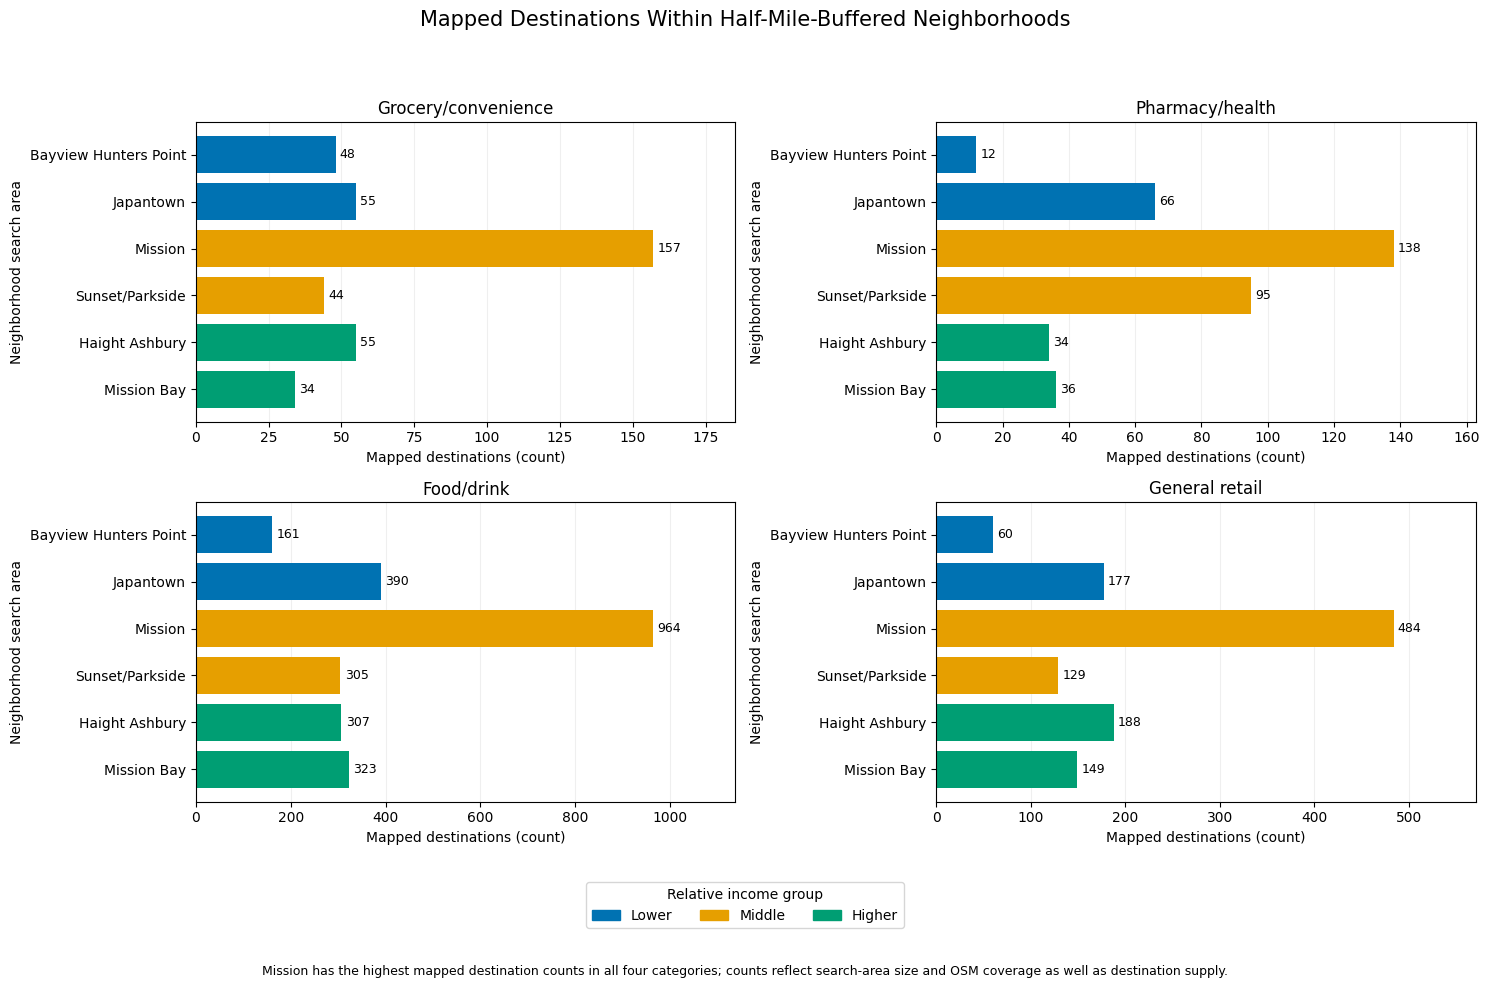

Saved: outputs/figures/destination_counts_by_search_area.png


In [51]:
# Compare destination counts across the six buffered search areas.
from matplotlib.patches import Patch

categories = list(category_columns.keys())
plot_data = search_area_summary.copy()

bar_colors = [
    income_colors[str(band)]
    for band in plot_data["income_band"]
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, category in zip(axes.flat, categories):
    bars = ax.barh(
        plot_data["search_neighborhood"],
        plot_data[category],
        color=bar_colors
    )

    ax.invert_yaxis()
    ax.set_title(category)
    ax.set_xlabel("Mapped destinations (count)")
    ax.set_ylabel("Neighborhood search area")
    ax.bar_label(bars, padding=3, fontsize=9)

    # Leave space for count labels beyond each bar.
    ax.set_xlim(0, plot_data[category].max() * 1.18)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Mapped Destinations Within Half-Mile-Buffered Neighborhoods",
    fontsize=15
)

fig.legend(
    handles=[
        Patch(color=income_colors[band], label=band)
        for band in ["Lower", "Middle", "Higher"]
    ],
    title="Relative income group",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.055),
    ncol=3
)

fig.text(
    0.5, 0.015,
    "Mission has the highest mapped destination counts in all four categories; "
    "counts reflect search-area size and OSM coverage as well as destination supply.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.13, 1, 0.94])

figure_path = Path(
    "outputs/figures/destination_counts_by_search_area.png"
)
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()
print("Saved:", figure_path)

### Opening-hours coverage

We measure opening-hours availability across the six search areas before analyzing time-of-day access. Missing hours remain unknown, rather than being treated as open or closed. A nonblank opening-hours tag does not necessarily contain a usable schedule.

In [52]:
# Check whether an opening-hours tag contains any text.
def has_opening_hours(series):
    return series.fillna("").astype(str).str.strip().ne("")


# Count each destination once within each neighborhood search area.
hours_matches = business_search_matches_clean.drop_duplicates(
    subset=["search_neighborhood", "osm_key"]
).copy()

hours_matches["hours_provided"] = has_opening_hours(
    hours_matches["opening_hours"]
)

hours_coverage_by_search_area = (
    hours_matches.groupby("search_neighborhood")
    .agg(
        destinations=("osm_key", "nunique"),
        hours_provided=("hours_provided", "sum")
    )
    .reset_index()
)

hours_coverage_by_search_area["hours_missing"] = (
    hours_coverage_by_search_area["destinations"]
    - hours_coverage_by_search_area["hours_provided"]
)

hours_coverage_by_search_area["hours_provided_pct"] = (
    100
    * hours_coverage_by_search_area["hours_provided"]
    / hours_coverage_by_search_area["destinations"]
)

# Attach income groups for comparison.
hours_coverage_by_search_area = (
    search_area_summary[["search_neighborhood", "income_band"]]
    .merge(
        hours_coverage_by_search_area,
        on="search_neighborhood",
        validate="one_to_one"
    )
)

hours_coverage_by_search_area.to_csv(
    "outputs/tables/opening_hours_coverage_by_search_area.csv",
    index=False
)

# Overall coverage counts each destination once across all search areas.
overall_hours = has_opening_hours(
    business_points_in_search["opening_hours"]
)

print("Distinct destinations:", len(overall_hours))
print("Opening hours provided:", overall_hours.sum())
print("Opening hours missing:", (~overall_hours).sum())
print(f"Overall hours availability: {overall_hours.mean():.1%}")

display(hours_coverage_by_search_area.round(2))

Distinct destinations: 3709
Opening hours provided: 1631
Opening hours missing: 2078
Overall hours availability: 44.0%


,search_neighborhood,income_band,destinations,hours_provided,hours_missing,hours_provided_pct
0,Bayview Hunters Point,Lower,281,95,186,33.81
1,Japantown,Lower,688,285,403,41.42
2,Mission,Middle,1740,839,901,48.22
3,Sunset/Parkside,Middle,573,169,404,29.49
4,Haight Ashbury,Higher,584,309,275,52.91
5,Mission Bay,Higher,540,290,250,53.70


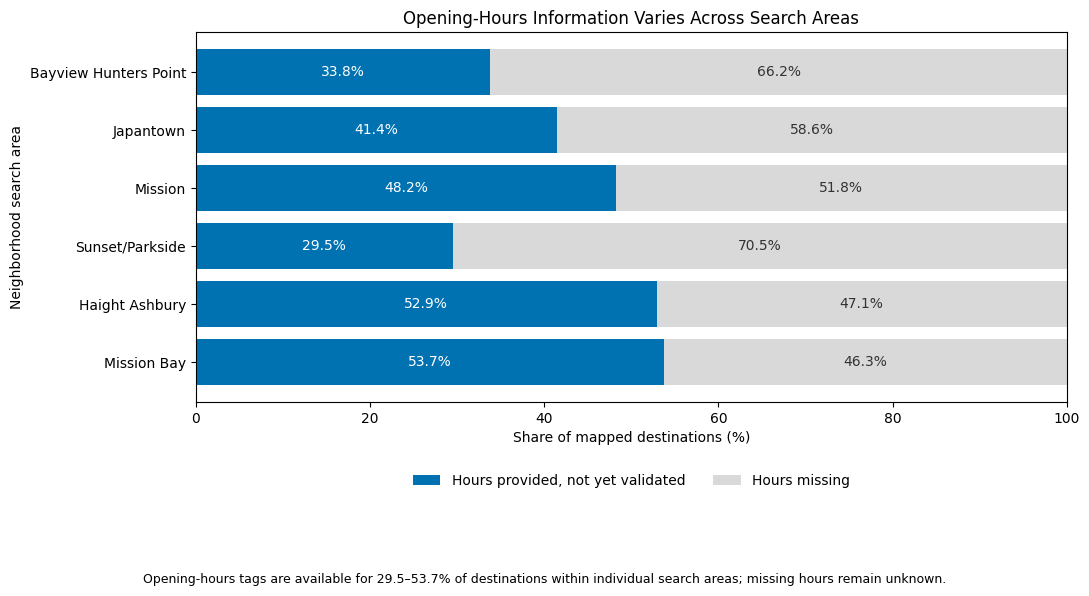

Saved: outputs/figures/opening_hours_coverage_by_search_area.png


In [53]:
# Show provided and missing opening-hours information as percentages.
coverage_plot = hours_coverage_by_search_area.copy()

provided_pct = coverage_plot["hours_provided_pct"]
missing_pct = 100 - provided_pct

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    coverage_plot["search_neighborhood"],
    provided_pct,
    color="#0072B2",
    label="Hours provided, not yet validated"
)

ax.barh(
    coverage_plot["search_neighborhood"],
    missing_pct,
    left=provided_pct,
    color="#d9d9d9",
    label="Hours missing"
)

# Label each segment with its percentage.
for position, (provided, missing) in enumerate(
    zip(provided_pct, missing_pct)
):
    ax.text(
        provided / 2, position, f"{provided:.1f}%",
        ha="center", va="center", color="white"
    )
    ax.text(
        provided + missing / 2, position, f"{missing:.1f}%",
        ha="center", va="center", color="#333333"
    )

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of mapped destinations (%)")
ax.set_ylabel("Neighborhood search area")
ax.set_title("Opening-Hours Information Varies Across Search Areas")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=2,
    frameon=False
)

fig.text(
    0.5, 0.02,
    "Opening-hours tags are available for 29.5–53.7% of destinations "
    "within individual search areas; missing hours remain unknown.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.12, 1, 1])

figure_path = Path(
    "outputs/figures/opening_hours_coverage_by_search_area.png"
)
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()
print("Saved:", figure_path)

In [54]:
# Inspect hours once per distinct destination, rather than once
# per overlapping neighborhood search area.
hours_inventory = business_points_in_search[
    ["osm_key", "name", "opening_hours"]
].copy()

# Trim surrounding whitespace without changing schedule contents.
hours_inventory["hours_text"] = (
    hours_inventory["opening_hours"]
    .fillna("")
    .astype(str)
    .str.strip()
)

provided_hours = hours_inventory.loc[
    hours_inventory["hours_text"].ne("")
].copy()

# Count how often each distinct schedule appears.
opening_hours_frequency = (
    provided_hours["hours_text"]
    .value_counts()
    .rename_axis("opening_hours")
    .reset_index(name="destination_count")
)

opening_hours_frequency.to_csv(
    "outputs/tables/opening_hours_string_frequency.csv",
    index=False
)

print("Destinations with hours:", len(provided_hours))
print("Distinct opening-hours strings:", len(opening_hours_frequency))

print("\nMost common opening-hours strings:")
with pd.option_context("display.max_colwidth", None):
    display(opening_hours_frequency.head(25))

# Long entries help us inspect schedules with multiple rules.
print("\nTen longest entries for inspection:")
longest_entries = (
    provided_hours.assign(
        text_length=provided_hours["hours_text"].str.len()
    )
    .sort_values(["text_length", "osm_key"], ascending=[False, True])
    .head(10)
)

with pd.option_context("display.max_colwidth", None):
    display(longest_entries[["osm_key", "name", "hours_text"]])

print("\nNo schedules have been classified as open or closed yet.")

Destinations with hours: 1631
Distinct opening-hours strings: 1313

Most common opening-hours strings:


,opening_hours,destination_count
0,24/7,19
1,Mo-Su 11:00-21:00,19
2,Mo-Su 11:00-19:00,13
3,Mo-Su 08:00-22:00,11
4,Mo-Fr 09:00-17:00,11
5,11:00-19:00,10
6,Mo-Su 08:00-21:00,9
7,Mo-Su 08:00-20:00,9
8,Mo-Su 11:00-22:00,9
9,Mo-Sa 10:00-18:00,7



Ten longest entries for inspection:


,osm_key,name,hours_text
547,node/2297205772,Serpentine,"Mo-We 17:00-22:00; Th 10:00-14:30, 17:00-22:00; Fr-Sa 10:00-14:30, 17:00-23:00; Su 10:00-14:30, ""supper enquire within"""
738,node/2937336925,Hayes Street Grill,"Th-Sa 11:30-14:30,17:00-21:00; Su 12:00-18:00; Mo-We 17:00-21:00 open ""on symphony/opera house performance nights only"""
2468,node/10309959742,B-Side,"We 11:30-14:00, Th,Fr 11:30-14:00, Th,Fr 17:30-20:30, Sa,Su 11:00-14:30, Sa 17:30-20:30, Su 17:00-20:00; Mo-Tu off"
3230,node/13816468429,Kiku Sushi & Vegetarian,"Mo off; Tu-Th 11:30-14:30,17:00-21:00; Fr 11:30-14:30,17:00-21:30; Sa 12:00-15:00,17:00-21:30; Su 17:00-21:30"
2236,node/9655240383,Baiano Pizzeria,Mo-Tu 10:00-19:00; We 10:00-20:00; Th 10:00-21:00; Fr 10:00-22:00; Sa 11:00-21:00; Su 11:00-20:00; PH off
694,node/2666409793,Susan Oyakawa,"Mo 08:00-12:30, 15:00-17:30; Tu 15:00-18:00; We 08:00-12:30, 15:00-17:30; Th 15:00-18:00; Fr 08:00-12:00"
3406,way/216220336,Thriller Social Club,Mo off; Tu 16:00-22:00; We 16:00-22:30; Th 16:00-23:30; Fr 16:00-25:00; Sa 17:00-25:00; Su 14:00-20:00
404,node/1809593827,Big 5 Sporting Goods,Mo-Tu 10:30-20:00; We 10:00-20:30; Th 10:30-18:30; Fr 09:30-21:00; Sa 10:30-19:00; Su 11:00-19:00
628,node/2501316103,Waraku,"Tu-Th 11:30-14:30,17:00-21:00; Fr 11:30-14:30,17:00-22:00; Sa 11:30-22:00; Su 11:30-21:00; Mo off"
1730,node/5497161847,Nojo Ramen Tavern,"Tu-Th 17:00-21:00; Fr 17:00-21:30; Sa 11:30-14:30,17:00-21:30; Su 11:30-14:30,16:00-20:00; Mo off"



No schedules have been classified as open or closed yet.


In [55]:
# Load the parser for OpenStreetMap opening-hours schedules.
from opening_hours import OpeningHours
from importlib.metadata import version

print("Opening-hours parser version:", version("opening-hours-py"))

# Confirm the parser can interpret a simple, always-open schedule.
test_schedule = OpeningHours("24/7")
print("24/7 test:", test_schedule.state())

Opening-hours parser version: 1.1.1
24/7 test: open


In [56]:
# Parse each distinct schedule once.
# Keep parser objects for later time-of-day calculations.
parsed_hours = {}
parse_records = []

for hours_text in opening_hours_frequency["opening_hours"]:
    try:
        schedule = OpeningHours(hours_text)
        parsed_hours[hours_text] = schedule

        # Comments can contain conditions the parser cannot resolve,
        # such as opening only on performance nights.
        has_comment = '"' in hours_text

        parse_records.append({
            "hours_text": hours_text,
            "parse_status": (
                "Parsed; comment needs review"
                if has_comment
                else "Parsed; no quoted comment"
            ),
            "parse_error": ""
        })

    except Exception as error:
        # Parsing failures remain unknown, rather than closed.
        parse_records.append({
            "hours_text": hours_text,
            "parse_status": "Not parsed",
            "parse_error": f"{type(error).__name__}: {error}"
        })

hours_parse_results = pd.DataFrame(parse_records)

# Attach results to every destination, including those missing hours.
business_hours_audit = hours_inventory.merge(
    hours_parse_results,
    on="hours_text",
    how="left",
    validate="many_to_one"
)

business_hours_audit["parse_status"] = (
    business_hours_audit["parse_status"].fillna("Missing hours")
)
business_hours_audit["parse_error"] = (
    business_hours_audit["parse_error"].fillna("")
)

business_hours_audit.to_csv(
    "outputs/tables/opening_hours_parse_audit.csv",
    index=False
)

print("Destination records by parsing status:")
display(business_hours_audit["parse_status"].value_counts())

# Display distinct schedules requiring closer inspection.
schedules_needing_review = hours_parse_results.loc[
    hours_parse_results["parse_status"].ne(
        "Parsed; no quoted comment"
    )
].copy()

print("\nDistinct schedules requiring review:", len(schedules_needing_review))

with pd.option_context("display.max_colwidth", None):
    display(schedules_needing_review.head(20))

print("\nNo destinations removed; no open/closed states assigned yet.")

Destination records by parsing status:


parse_status
Missing hours                   2078
Parsed; no quoted comment       1601
Parsed; comment needs review      26
Not parsed                         4
Name: count, dtype: int64


Distinct schedules requiring review: 26


,hours_text,parse_status,parse_error
52,"""by appointment""",Parsed; comment needs review,
82,"""By appointment only""",Parsed; comment needs review,
88,"""by appointment only""",Parsed; comment needs review,
131,"closed ""Temporarily closed""",Parsed; comment needs review,
155,"Mo-Fr 10:00-18:00; Sa 11:00-17:00; Su off ""by appointment""",Parsed; comment needs review,
338,"We-Sa 11:00-18:00 ""by appt, limited walk-in""; Su 11:00-17:00 ""by appt, limited walk-in""",Parsed; comment needs review,
371,"We-Su ""by appointment""",Parsed; comment needs review,
459,"Mo-Fr ""by appointment""",Parsed; comment needs review,
499,"Mo-Fr ""By appointment""",Parsed; comment needs review,
577,"Mo-Fr 08:30-18:00, Sa-Su closed,PH off",Not parsed,"ParserError: Failed to parse expression: --> 1:32\n |\n1 | Mo-Fr 08:30-18:00, Sa-Su closed,PH off\n | ^---\n |\n = expected EOI, any_rule_separator, or comment"



No destinations removed; no open/closed states assigned yet.


In [57]:
# Make only these documented punctuation corrections.
# Commas within split shifts, such as 12:00-14:00,17:00-21:00,
# are preserved.
hours_correction_log = pd.DataFrame(
    [
        (
            "Mo-Fr 08:30-18:00, Sa-Su closed,PH off",
            "Mo-Fr 08:30-18:00; Sa-Su closed; PH off"
        ),
        (
            "Mo,Su off; Tu-Fr 09:30-16:30,Sa 10:00-16:00",
            "Mo,Su off; Tu-Fr 09:30-16:30; Sa 10:00-16:00"
        ),
        (
            "We-Sa 11:30-22:00,Su 11:00-21:00",
            "We-Sa 11:30-22:00; Su 11:00-21:00"
        ),
        (
            "Tu-Fr 10:00-18:00,Sa 11:00-17:00",
            "Tu-Fr 10:00-18:00; Sa 11:00-17:00"
        )
    ],
    columns=["original_hours", "corrected_hours"]
)

hours_correction_log["reason"] = (
    "Replace commas separating day rules with semicolons; "
    "retain the stated days and times."
)

# Record the actual expression used without overwriting source text.
hours_parse_results["evaluated_hours_text"] = (
    hours_parse_results["hours_text"]
)

for correction in hours_correction_log.itertuples(index=False):
    mask = hours_parse_results["hours_text"].eq(
        correction.original_hours
    )
    assert mask.sum() == 1

    # Stop visibly if a proposed correction still fails to parse.
    corrected_schedule = OpeningHours(correction.corrected_hours)

    # Keep the original string as the lookup key.
    parsed_hours[correction.original_hours] = corrected_schedule

    hours_parse_results.loc[mask, "evaluated_hours_text"] = (
        correction.corrected_hours
    )
    hours_parse_results.loc[mask, "parse_status"] = (
        "Parsed after documented punctuation repair"
    )
    hours_parse_results.loc[mask, "parse_error"] = ""

# Rebuild the destination audit with the updated parsing results.
business_hours_audit = hours_inventory.merge(
    hours_parse_results,
    on="hours_text",
    how="left",
    validate="many_to_one"
)

business_hours_audit["parse_status"] = (
    business_hours_audit["parse_status"].fillna("Missing hours")
)

hours_correction_log.to_csv(
    "outputs/tables/opening_hours_corrections.csv",
    index=False
)
business_hours_audit.to_csv(
    "outputs/tables/opening_hours_parse_audit.csv",
    index=False
)

display(business_hours_audit["parse_status"].value_counts())
print("Original opening-hours text preserved.")

parse_status
Missing hours                                 2078
Parsed; no quoted comment                     1601
Parsed; comment needs review                    26
Parsed after documented punctuation repair       4
Name: count, dtype: int64

Original opening-hours text preserved.


In [59]:
# Select schedules eligible for time-of-day evaluation.
# Missing or ambiguous schedules remain in the full destination data.
accepted_parse_statuses = [
    "Parsed; no quoted comment",
    "Parsed after documented punctuation repair"
]

business_hours_audit["eligible_for_schedule_evaluation"] = (
    business_hours_audit["parse_status"].isin(
        accepted_parse_statuses
    )
)

hour_evaluation_candidates = business_hours_audit.loc[
    business_hours_audit["eligible_for_schedule_evaluation"]
].copy()

business_hours_audit.to_csv(
    "outputs/tables/opening_hours_parse_audit.csv",
    index=False
)

print("Destinations retained overall:", len(business_hours_audit))
print("Schedules eligible for evaluation:", len(hour_evaluation_candidates))
print(
    "Destinations with missing or unresolved hours:",
    (~business_hours_audit["eligible_for_schedule_evaluation"]).sum()
)

Destinations retained overall: 3709
Schedules eligible for evaluation: 1605
Destinations with missing or unresolved hours: 2104


We set aside 26 destinations with quoted opening-hours comments from automated time-of-day evaluation. Together with 2,078 destinations missing hours, these remain in the destination dataset with unknown availability. We evaluate the remaining 1,605 schedules, including four with documented punctuation repairs. Results describe recorded schedules rather than verified operating hours.

In [60]:
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo

SF_TIMEZONE = ZoneInfo("America/Los_Angeles")

# Fix the dates so rerunning the notebook gives comparable results.
ANALYSIS_DATES = {
    "Wednesday": "2026-10-21",
    "Saturday": "2026-10-24"
}

time_records = []

for day_label, date_text in ANALYSIS_DATES.items():
    start = datetime.fromisoformat(
        f"{date_text}T06:00:00"
    ).replace(tzinfo=SF_TIMEZONE)

    assert start.strftime("%A") == day_label

    # Include 06:00 through 24:00: 37 evaluation times per day.
    # The final timestamp is midnight at the start of the next day.
    for step in range(37):
        timestamp = start + timedelta(minutes=30 * step)

        time_records.append({
            "analysis_day": day_label,
            "analysis_date": date_text,
            "minutes_since_midnight": 360 + 30 * step,
            "time_label": (
                "24:00" if step == 36
                else timestamp.strftime("%H:%M")
            ),
            "timestamp_local": timestamp
        })

analysis_time_grid = pd.DataFrame(time_records)

analysis_time_grid.to_csv(
    "outputs/tables/analysis_time_grid.csv",
    index=False
)

print("Time zone:", SF_TIMEZONE)
print("Evaluation times per day:")
display(analysis_time_grid.groupby("analysis_day").size())

display(
    analysis_time_grid.groupby("analysis_day", sort=False)
    .agg(
        first_time=("time_label", "first"),
        last_time=("time_label", "last")
    )
)

Time zone: America/Los_Angeles
Evaluation times per day:


analysis_day
Saturday     37
Wednesday    37
dtype: int64

,first_time,last_time
analysis_day,,
Wednesday,06:00,24:00
Saturday,06:00,24:00


In [61]:
import re

# Give each evaluation time a unique column name.
evaluation_grid = analysis_time_grid.copy()
evaluation_grid["slot_id"] = (
    evaluation_grid["analysis_day"]
    + "_"
    + evaluation_grid["time_label"]
)

# Attach the audited schedules to destination coordinates.
evaluation_inputs = business_points_in_search[
    ["osm_key", "geometry"]
].merge(
    business_hours_audit[
        ["osm_key", "evaluated_hours_text",
         "eligible_for_schedule_evaluation"]
    ],
    on="osm_key",
    validate="one_to_one"
).to_crs(epsg=4326)

# Start with unknown for every destination and evaluation time.
# This preserves businesses without usable hours.
business_time_states = pd.DataFrame(
    "unknown",
    index=evaluation_inputs["osm_key"],
    columns=evaluation_grid["slot_id"]
)
business_time_states.index.name = "osm_key"

evaluation_times = [
    timestamp.to_pydatetime()
    for timestamp in evaluation_grid["timestamp_local"]
]


def evaluate_recorded_schedule(hours_text, point, times):
    # School holidays require a local calendar we have not supplied.
    if re.search(r"\bSH\b", hours_text):
        raise ValueError("School-holiday calendar requires further review.")

    schedule = OpeningHours(
        hours_text,
        timezone=SF_TIMEZONE,
        country="US",
        coords=(point.y, point.x)  # Latitude, longitude.
    )

    states = []
    for timestamp in times:
        if schedule.is_open(timestamp):
            states.append("open")
        elif schedule.is_closed(timestamp):
            states.append("closed")
        else:
            states.append("unknown")

    return states


evaluation_issues = []

eligible_inputs = evaluation_inputs.loc[
    evaluation_inputs["eligible_for_schedule_evaluation"]
]

for _, row in eligible_inputs.iterrows():
    try:
        states = evaluate_recorded_schedule(
            row["evaluated_hours_text"],
            row.geometry,
            evaluation_times
        )
        business_time_states.loc[row["osm_key"], :] = states

    except Exception as error:
        # Keep all times unknown for this destination and log the issue.
        evaluation_issues.append({
            "osm_key": row["osm_key"],
            "hours_text": row["evaluated_hours_text"],
            "issue": f"{type(error).__name__}: {error}"
        })

evaluation_issue_log = pd.DataFrame(
    evaluation_issues,
    columns=["osm_key", "hours_text", "issue"]
)

# Save a compact table: one destination per row, one time per column.
business_time_states.to_csv(
    "data/processed/business_recorded_opening_states.csv"
)
evaluation_grid.to_csv(
    "outputs/tables/analysis_time_grid.csv",
    index=False
)
evaluation_issue_log.to_csv(
    "outputs/tables/opening_hours_evaluation_issues.csv",
    index=False
)

assert business_time_states.shape == (3709, 74)

print("Destinations retained:", len(business_time_states))
print("Evaluation times:", len(business_time_states.columns))
print("Schedules with evaluation issues:", len(evaluation_issue_log))

print("\nRecorded states at noon:")
display(
    business_time_states[
        ["Wednesday_12:00", "Saturday_12:00"]
    ]
    .apply(lambda column: column.value_counts())
    .fillna(0)
    .astype(int)
    .reindex(["open", "closed", "unknown"], fill_value=0)
)

if not evaluation_issue_log.empty:
    display(evaluation_issue_log)

Destinations retained: 3709
Evaluation times: 74
Schedules with evaluation issues: 0

Recorded states at noon:


slot_id,Wednesday_12:00,Saturday_12:00
open,1322,1302
closed,283,303
unknown,2104,2104


In [62]:
# Summarize recorded states within each neighborhood search area.
# Count each destination once per search area.
area_membership = business_search_matches_clean[
    ["search_neighborhood", "osm_key"]
].drop_duplicates()

area_time_tables = []

for neighborhood, members in area_membership.groupby(
    "search_neighborhood"
):
    area_states = business_time_states.loc[members["osm_key"]]

    counts = pd.DataFrame({
        "recorded_open": area_states.eq("open").sum(),
        "recorded_closed": area_states.eq("closed").sum(),
        "unknown": area_states.eq("unknown").sum()
    }).rename_axis("slot_id").reset_index()

    counts["search_neighborhood"] = neighborhood
    counts["total_destinations"] = len(area_states)

    # Keep unknown destinations in the denominator.
    # This measures the share recorded as open, not the true open share.
    counts["recorded_open_pct"] = (
        100 * counts["recorded_open"] / counts["total_destinations"]
    )

    area_time_tables.append(counts)

destination_availability_by_time = pd.concat(
    area_time_tables,
    ignore_index=True
).merge(
    evaluation_grid,
    on="slot_id",
    validate="many_to_one"
)

# Verify that open, closed, and unknown account for every destination.
assert (
    destination_availability_by_time[
        ["recorded_open", "recorded_closed", "unknown"]
    ].sum(axis=1)
    == destination_availability_by_time["total_destinations"]
).all()

destination_availability_by_time.to_csv(
    "outputs/tables/recorded_destination_availability_by_time.csv",
    index=False
)

print("Neighborhood–time summaries:", len(destination_availability_by_time))
print("\nRecorded open destinations at noon:")

display(
    destination_availability_by_time.loc[
        destination_availability_by_time["time_label"].eq("12:00")
    ].pivot(
        index="search_neighborhood",
        columns="analysis_day",
        values="recorded_open"
    )
)

Neighborhood–time summaries: 444

Recorded open destinations at noon:


analysis_day,Saturday,Wednesday
search_neighborhood,,
Bayview Hunters Point,73,78
Haight Ashbury,260,255
Japantown,228,231
Mission,651,658
Mission Bay,211,251
Sunset/Parkside,147,139


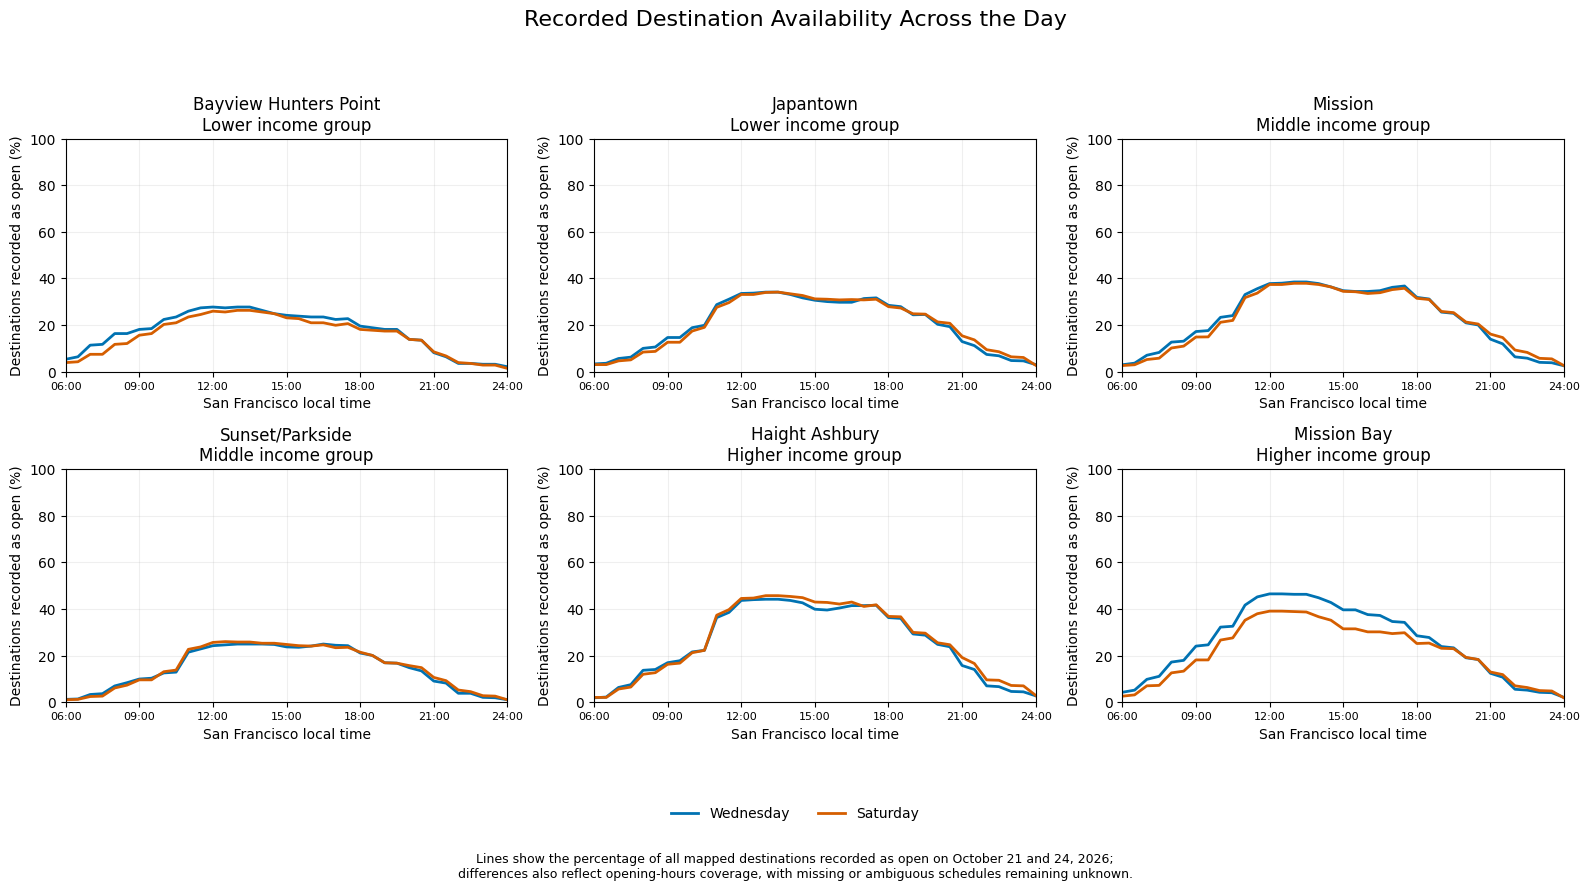

Saved: outputs/figures/recorded_destination_availability_by_time.png


In [63]:
# Compare the share of destinations recorded as open throughout the day.
# Unknown hours remain in the denominator and are not classified as closed.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

day_colors = {
    "Wednesday": "#0072B2",
    "Saturday": "#D55E00"
}

for ax, (_, area) in zip(
    axes.flat,
    search_area_summary.iterrows()
):
    neighborhood = area["search_neighborhood"]
    income_band = str(area["income_band"])

    area_data = destination_availability_by_time.loc[
        destination_availability_by_time["search_neighborhood"].eq(
            neighborhood
        )
    ]

    for day, color in day_colors.items():
        day_data = area_data.loc[
            area_data["analysis_day"].eq(day)
        ].sort_values("minutes_since_midnight")

        ax.plot(
            day_data["minutes_since_midnight"] / 60,
            day_data["recorded_open_pct"],
            color=color,
            linewidth=2,
            label=day
        )

    ax.set_title(f"{neighborhood}\n{income_band} income group")
    ax.set_xlim(6, 24)
    ax.set_ylim(0, 100)
    ax.set_xticks([6, 9, 12, 15, 18, 21, 24])
    ax.set_xticklabels(
        ["06:00", "09:00", "12:00", "15:00",
         "18:00", "21:00", "24:00"],
        fontsize=8
    )
    ax.set_xlabel("San Francisco local time")
    ax.set_ylabel("Destinations recorded as open (%)")
    ax.grid(alpha=0.2)

fig.suptitle(
    "Recorded Destination Availability Across the Day",
    fontsize=16
)

# Use one shared legend for all six panels.
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.065),
    ncol=2,
    frameon=False
)

fig.text(
    0.5, 0.015,
    "Lines show the percentage of all mapped destinations recorded as open "
    "on October 21 and 24, 2026;\n"
    "differences also reflect opening-hours coverage, with missing or "
    "ambiguous schedules remaining unknown.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.15, 1, 0.94])

figure_path = Path(
    "outputs/figures/recorded_destination_availability_by_time.png"
)
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()
print("Saved:", figure_path)

### Saved analysis datasets

We save cleaned destination points with their source identifiers, categories, original opening-hours text, and schedule-evaluation status. A separate membership table records which buffered search areas contain each destination. Spatial exports use EPSG:4326; distance and buffer calculations were performed in EPSG:26910.

In [64]:
processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Export selected scalar fields, excluding temporary token-list columns.
destination_columns = [
    "osm_key", "source_osm_keys", "osm_element", "osm_id",
    "name", "shop", "amenity", "healthcare",
    "source_geometry_type", "opening_hours",
    *flag_columns, "category_count", "geometry"
]

clean_business_points = business_points_in_search[
    destination_columns
].merge(
    business_hours_audit[
        ["osm_key", "evaluated_hours_text", "parse_status",
         "eligible_for_schedule_evaluation"]
    ],
    on="osm_key",
    how="left",
    validate="one_to_one"
).to_crs(epsg=4326)

assert clean_business_points["osm_key"].is_unique
assert len(clean_business_points) == 3709

# Preserve the cleaned points and their audit information.
destination_file = processed_dir / "osm_destinations_clean.geojson"
destination_file.write_text(
    clean_business_points.to_json(drop_id=True),
    encoding="utf-8"
)

# Save destination membership without duplicating geometry.
membership_export = business_search_matches_clean[
    ["osm_key", "search_neighborhood", "search_income_band"]
].drop_duplicates()

membership_file = processed_dir / "destination_search_area_membership.csv"
membership_export.to_csv(membership_file, index=False)

# Save both the original study boundaries and the buffered search areas.
spatial_exports = {
    "selected_neighborhood_boundaries.geojson": study_neighborhoods,
    "neighborhood_search_areas.geojson": business_search_areas
}

for filename, dataset in spatial_exports.items():
    export_data = dataset[
        ["nhood", "income_band", "geometry"]
    ].to_crs(epsg=4326)

    destination = processed_dir / filename
    destination.write_text(
        export_data.to_json(drop_id=True),
        encoding="utf-8"
    )
    print("Saved:", destination)

print("Saved:", destination_file, f"({len(clean_business_points):,} destinations)")
print("Saved:", membership_file, f"({len(membership_export):,} memberships)")

Saved: data/processed/selected_neighborhood_boundaries.geojson
Saved: data/processed/neighborhood_search_areas.geojson
Saved: data/processed/osm_destinations_clean.geojson (3,709 destinations)
Saved: data/processed/destination_search_area_membership.csv (4,406 memberships)


In [65]:
# Count records held for unresolved classification after manual review.
category_records_held = (
    len(businesses_eligible)
    - len(scope_exclusions)
    - len(businesses_in_scope)
)
assert category_records_held >= 0

# Record the sequential cleaning process.
# "Merged" counts redundant representations removed from the dataset.
business_cleaning_summary = pd.DataFrame(
    [
        (
            "Status screening",
            len(businesses_work),
            len(businesses_excluded),
            len(businesses_needing_review),
            0,
            len(businesses_eligible),
            "Exclude vacant, disused, or restricted destinations; "
            "hold conflicting status tags for review."
        ),
        (
            "Category screening and manual review",
            len(businesses_eligible),
            len(scope_exclusions),
            category_records_held,
            0,
            len(businesses_in_scope),
            "Retain destinations matching project categories; "
            "exclude out-of-scope services and shopping-centre aggregates; "
            "hold unresolved classifications."
        ),
        (
            "Unresolved duplicate screening",
            len(businesses_in_scope),
            len(uncertain_duplicate_exclusions),
            0,
            0,
            len(businesses_after_duplicate_review),
            "Exclude both records in eight unresolved duplicate pairs."
        ),
        (
            "Duplicate merging",
            len(businesses_after_duplicate_review),
            0,
            0,
            len(duplicate_merge_log),
            len(businesses_deduplicated),
            "Combine three duplicate pairs while preserving source identifiers."
        ),
        (
            "Search-area boundary filtering",
            len(businesses_deduplicated),
            len(boundary_exclusion_log),
            0,
            0,
            len(business_points_in_search),
            "Exclude the destination whose representative point lies "
            "outside all search areas."
        )
    ],
    columns=[
        "step", "records_before", "records_excluded",
        "records_held_for_review", "representations_merged",
        "records_retained", "reason"
    ]
)

# Verify that each stage accounts for all its input records.
assert (
    business_cleaning_summary["records_before"]
    - business_cleaning_summary["records_excluded"]
    - business_cleaning_summary["records_held_for_review"]
    - business_cleaning_summary["representations_merged"]
    == business_cleaning_summary["records_retained"]
).all()

business_cleaning_summary.to_csv(
    "outputs/tables/business_cleaning_summary.csv",
    index=False
)

# Preserve supporting logs that were previously held in notebook memory.
supporting_logs = {
    "business_status_summary.csv": business_status_log,
    "business_tag_normalization_log.csv": business_tag_normalization_log,
    "manual_category_review_log.csv": manual_category_review_log
}

for filename, table in supporting_logs.items():
    table.to_csv(Path("outputs/tables") / filename, index=False)

display(business_cleaning_summary)

print("Raw candidates:", len(businesses_work))
print("Final destination records:", len(business_points_in_search))
print(
    "Retained destinations with missing or unresolved hours:",
    (~business_hours_audit["eligible_for_schedule_evaluation"]).sum()
)
print("Missing or ambiguous hours did not remove destination records.")

,step,records_before,records_excluded,records_held_for_review,representations_merged,records_retained,reason
0,Status screening,4797,109,11,0,4677,"Exclude vacant, disused, or restricted destina..."
1,Category screening and manual review,4677,878,70,0,3729,Retain destinations matching project categorie...
2,Unresolved duplicate screening,3729,16,0,0,3713,Exclude both records in eight unresolved dupli...
3,Duplicate merging,3713,0,0,3,3710,Combine three duplicate pairs while preserving...
4,Search-area boundary filtering,3710,1,0,0,3709,Exclude the destination whose representative p...


Raw candidates: 4797
Final destination records: 3709
Retained destinations with missing or unresolved hours: 2104
Missing or ambiguous hours did not remove destination records.
